In [1]:
# Install requirements
!pip install -U peft datasets transformers accelerate bitsandbytes
!pip install xformers ipywidgets tqdm
!pip install git+https://github.com/huggingface/diffusers.git
!pip install opencv-python-headless seaborn scikit-learn scipy scikit-image
!pip install plotly

import os
os.environ["BNB_CUDA_VERSION"] = "130"
os.environ["LD_LIBRARY_PATH"] = "/usr/local/cuda/lib64"

import torch
from datasets import load_dataset
from diffusers import StableDiffusionPipeline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 680.7/680.7 kB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 16.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 16.6 MB/s  0:00:03m0:00:0100:01
  Attempting uninstall: safetensors
    Found existing installation: safetensors 0.7.0
    Uninstalling safetensors-0.7.0:
      Successfully uninstalled safetensors-0.7.0
  Attempting uninstall: datasetsm━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [bitsandbytes]
    Found existing installation: datasets 4.8.4━━━━━━━━━━━━━━━ 1/6 [bitsandbytes]
    Uninstalling datasets-4.8.4:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/6 [bitsandbytes]
      Successfully uninstalled datasets-4.8.4━━━━━━━━━━━━━━━━━━━━━ 2/6 [datasets]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [peft]5/6 [peft]formers]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 16.3 MB/s  0:00:00 eta 0:00:01
   ━

This can be used to load a bitsandbytes version built with a CUDA version that is different from the PyTorch CUDA version.
If this was unintended set the BNB_CUDA_VERSION variable to an empty string: export BNB_CUDA_VERSION=

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0a0+0291f960b6.nv26.04.48445190)
    Python  3.10.19 (you have 3.12.3)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details


In [3]:
!wget https://raw.githubusercontent.com/huggingface/diffusers/main/examples/text_to_image/train_text_to_image_lora.py

--2026-07-16 14:25:07--  https://raw.githubusercontent.com/huggingface/diffusers/main/examples/text_to_image/train_text_to_image_lora.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 43234 (42K) [text/plain]
Saving to: ‘train_text_to_image_lora.py.1’

train_text_to_image 100%[===================>]  42.22K  --.-KB/s    in 0.009s  

2026-07-16 14:25:07 (4.74 MB/s) - ‘train_text_to_image_lora.py.1’ saved [43234/43234]



### Actual Run

In [4]:
import os
import json
import pandas as pd

def generate_unified_baselines(
    csv_path="riboflavin_features_new.csv", 
    output_json="concentration_baselines.json"
):
    print("📖 Loading pre-extracted lab features...")
    df_features = pd.read_csv(csv_path)
    df_features.columns = df_features.columns.str.strip()
    
    # Clean missing values
    df_features = df_features.dropna()
    df_features['label'] = df_features['label'].astype(float)

    # 1. Re-run the exact same clustering logic inside this container 
    # to guarantee 100% flawless row alignment without parsing text strings
    df_features["sub_morphology_cluster"] = 0
    from sklearn.preprocessing import StandardScaler
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score

    non_feature_cols = ['filename', 'label', 'sub_morphology_cluster']
    feature_columns = [col for col in df_features.columns if col not in non_feature_cols]
    concentration_profiles = sorted(df_features['label'].unique())

    print("🔮 Syncing unsupervised discovery clusters...")
    for conc in concentration_profiles:
        subset_mask = df_features['label'] == conc
        subset_idx = df_features[subset_mask].index
        
        if len(subset_idx) < 4:
            continue
            
        X = df_features.loc[subset_idx, feature_columns].values
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        
        best_k = 1
        best_score = -1
        for k in [2, 3]:
            if len(X_scaled) > k:
                km = KMeans(n_clusters=k, random_state=42, n_init=10)
                labels = km.fit_predict(X_scaled)
                score = silhouette_score(X_scaled, labels)
                if score > best_score:
                    best_score = score
                    best_k = k
                    
        if best_k > 1 and best_score > 0.22:
            final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
            df_features.loc[subset_idx, "sub_morphology_cluster"] = final_km.fit_predict(X_scaled)

    # 2. Map and Standardize concentration labels into strings matching training profiles
    def standardize_conc_str(conc_float):
        if conc_float in [6.5, 6.50, 6.25]:
            return "6.25"
        # Truncate whole floats to integers (e.g., 1.0 -> "1", 100.0 -> "100")
        return str(int(conc_float)) if conc_float.is_integer() else str(conc_float)

    df_features['extracted_conc'] = df_features['label'].apply(standardize_conc_str)

    # 3. Group and compute stats safely
    print("📊 Computing aggregated profile distributions...")
    stats = df_features.groupby(['extracted_conc', 'sub_morphology_cluster'])[feature_columns].agg(['mean', 'std'])

    # 4. Construct structural baseline dictionary
    baseline_dict = {}
    for (conc_str, morph_type) in stats.index:
        composite_key = f"{conc_str}_type_{int(morph_type)}"
        baseline_dict[composite_key] = {}
        
        for col in feature_columns:
            mean_val = stats.loc[(conc_str, morph_type), (col, 'mean')]
            std_val = stats.loc[(conc_str, morph_type), (col, 'std')]
            
            # Prevent zero-variance clipping issues
            if pd.isna(std_val) or std_val == 0:
                std_val = 1e-5
                
            baseline_dict[composite_key][col] = {
                "mean": float(mean_val),
                "std": float(std_val)
            }

    with open(output_json, 'w') as f_out:
        json.dump(baseline_dict, f_out, indent=4)
        
    print(f"\n✅ Success! Multi-Morphology targets matched and written to {output_json}!")
    print(f"Total verified composite keys compiled: {len(baseline_dict)}")
    print(f"Active specialized keys list: {sorted(list(baseline_dict.keys()))}")

if __name__ == "__main__":
    generate_unified_baselines()

📖 Loading pre-extracted lab features...
🔮 Syncing unsupervised discovery clusters...
📊 Computing aggregated profile distributions...

✅ Success! Multi-Morphology targets matched and written to concentration_baselines.json!
Total verified composite keys compiled: 12
Active specialized keys list: ['100_type_0', '12.5_type_0', '12.5_type_1', '1_type_0', '1_type_1', '25_type_0', '25_type_1', '25_type_2', '50_type_0', '50_type_1', '6_type_0', '6_type_1']


In [6]:
# import os
# import json
# import shutil

# # --- CONFIGURATION ---
# RAW_DATA_DIR = "./New_Riboflavin_Data"       # Path to your raw nested folders
# MASTER_TRAIN_DIR = "./new_riboflavin_train_ready"
# # ---------------------

# print(f"Scanning raw folders in '{RAW_DATA_DIR}' to compile master dataset...")

# # Clean slate for the master directory
# if os.path.exists(MASTER_TRAIN_DIR):
#     shutil.rmtree(MASTER_TRAIN_DIR)
# os.makedirs(MASTER_TRAIN_DIR, exist_ok=True)

# master_metadata_path = os.path.join(MASTER_TRAIN_DIR, "metadata.jsonl")
# image_count = 0

# with open(master_metadata_path, 'w') as f_master:
#     # Iterate through each concentration folder (1, 3, 6, etc.)
#     for conc_folder in os.listdir(RAW_DATA_DIR):
#         folder_path = os.path.join(RAW_DATA_DIR, conc_folder)
        
#         # Skip files, only process directories
#         if not os.path.isdir(folder_path):
#             continue
            
#         # Clean whitespaces and normalize folder name to standard float string format
#         # This translates folder "1" or "1.0" into a reliable, standardized "1.0" key
#         try:
#             clean_conc = f"{float(conc_folder.strip()):.1f}"
#         except ValueError:
#             clean_conc = conc_folder.strip() # Fallback if it's a non-numeric string
            
#         print(f" -> Indexing concentration folder: '{conc_folder}' -> Normalized as: '{clean_conc}'")
        
#         for filename in os.listdir(folder_path):
#             # Target image files
#             if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.tiff', '.bmp')):
#                 # Namespace files with their normalized concentration prefix to prevent overwriting duplicate names
#                 unique_filename = f"conc_{clean_conc}_{filename}"
                
#                 src_image_path = os.path.join(folder_path, filename)
#                 dst_image_path = os.path.join(MASTER_TRAIN_DIR, unique_filename)
                
#                 # Copy the file over
#                 shutil.copy2(src_image_path, dst_image_path)
                
#                 # Format the text caption to perfectly match your regex expectations downstream
#                 # This explicitly outputs "concentration 1.0", "concentration 12.5", etc.
#                 caption_text = f"a microscopic photo of a ribo_crystal crystallization, concentration {clean_conc}"
                
#                 # Structure and write the line to metadata.jsonl
#                 metadata_entry = {"file_name": unique_filename, "text": caption_text}
#                 f_master.write(json.dumps(metadata_entry) + "\n")
#                 image_count += 1

# print(f"\n✓ Master dataset successfully compiled!")
# print(f"Total raw images indexed: {image_count}")
# print(f"Output directory: {MASTER_TRAIN_DIR}")

Scanning raw folders in './New_Riboflavin_Data' to compile master dataset...
 -> Indexing concentration folder: '1' -> Normalized as: '1.0'
 -> Indexing concentration folder: '100' -> Normalized as: '100.0'
 -> Indexing concentration folder: '12.5' -> Normalized as: '12.5'
 -> Indexing concentration folder: '25' -> Normalized as: '25.0'
 -> Indexing concentration folder: '50' -> Normalized as: '50.0'
 -> Indexing concentration folder: '6' -> Normalized as: '6.0'

✓ Master dataset successfully compiled!
Total raw images indexed: 3108
Output directory: ./new_riboflavin_train_ready


#### training


In [6]:
import os
import json
import shutil
from PIL import Image
from tqdm import tqdm

# --- CONFIGURATION ---
# Points directly to your updated clean folder structure
SOURCE_DATA_DIR = "./Riboflavin_NAOH_Water_Dilution"
GLOBAL_AUG_DIR = "./work_space_unified_augmented"
OUTPUT_DIR = "./lora_riboflavin_unified_model"
# ---------------------

# Target concentrations based on your exact renamed folder names
TARGET_CONCENTRATIONS = ["1", "6.25", "12.5", "25"]

print("🏭 Starting Automated Unified LoRA Production Run (NAOH Structure)...")
print(f"📦 Target Outputs: Single master model capturing multi-type mutations.")

# Reset global workspace areas
for path in [GLOBAL_AUG_DIR, OUTPUT_DIR]:
    if os.path.exists(path):
        shutil.rmtree(path)
    os.makedirs(path, exist_ok=True)

# 1. Direct Folder Crawl & Auto-Captioning
all_entries = []

for root, dirs, files in os.walk(SOURCE_DATA_DIR):
    folder_name = os.path.basename(root)
    
    # Verify folder matches expected clean target concentrations
    if folder_name not in TARGET_CONCENTRATIONS:
        continue
        
    bmp_files = [f for f in files if f.lower().endswith(".bmp")]
    
    for filename in bmp_files:
        img_path = os.path.join(root, filename)
        
        # Build training prompt description context dynamically from folder structures
        # (Defaults to type_1 morphology, update if you require multi-type logic mappings)
        caption = f"a microscopic photo of a ribo_crystal crystallization, concentration {folder_name}, type_1 morphology"
        
        all_entries.append({
            "absolute_path": img_path,
            "filename": filename,
            "concentration": folder_name,
            "text": caption
        })

print(f"📊 Discovered a global pool of {len(all_entries)} source image files.")

# 2. Run the Global Augmentation Engine
aug_metadata_path = os.path.join(GLOBAL_AUG_DIR, "metadata.jsonl")
generated_count = 0

with open(aug_metadata_path, 'w') as f_out:
    for item in tqdm(all_entries, desc="└─ Processing Global Crystal Dataset"):
        img_path = item["absolute_path"]
        caption = item["text"]
        
        if not os.path.exists(img_path):
            continue
            
        base_name, ext = os.path.splitext(item["filename"])
        # Adding folder prefix to prevent filename overlap conflicts during pooling
        unique_prefix = f"conc_{item['concentration']}_{base_name}"
        
        try:
            with Image.open(img_path) as img:
                # Convert grayscale / index maps cleanly to RGB for Stable Diffusion baseline
                if img.mode != "RGB":
                    img = img.convert("RGB")
                    
                w, h = img.size
                min_dim = min(w, h)
                left = (w - min_dim) // 2
                top = (h - min_dim) // 2
                square_img = img.crop((left, top, left + min_dim, top + min_dim))
                small_img = square_img.resize((512, 512), Image.Resampling.BICUBIC)
                
                transforms = {
                    "orig": small_img,
                    "hflip": small_img.transpose(Image.FLIP_LEFT_RIGHT),
                    "vflip": small_img.transpose(Image.FLIP_TOP_BOTTOM),
                    "r90": small_img.transpose(Image.ROTATE_90),
                    "r180": small_img.transpose(Image.ROTATE_180),
                    "r270": small_img.transpose(Image.ROTATE_270),
                    "r90_hflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_LEFT_RIGHT),
                    "r90_vflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_TOP_BOTTOM)
                }
                
                for suffix, transformed_img in transforms.items():
                    # Exporting images explicitly as standard JPEG targets for training efficiency
                    new_img_name = f"{unique_prefix}_{suffix}.jpg"
                    transformed_img.save(os.path.join(GLOBAL_AUG_DIR, new_img_name), quality=95)
                    
                    new_data = {"file_name": new_img_name, "text": caption}
                    f_out.write(json.dumps(new_data) + "\n")
                    generated_count += 1
        except Exception as e:
            print(f"⚠️ Skipping corrupt image file {img_path}: {e}")
            continue

print(f"✅ Generated {generated_count} tailored 512x512 multi-conditional training samples.")

# 3. Unified Subprocess Training Job Submission
print(f"🏋️ Submitting combined matrix dataset to accelerator...")

# General baseline validation prompt matching structural target
v_prompt = "a microscopic photo of a ribo_crystal crystallization, concentration 25.0, type_1 morphology"

# CHANGED: Using 'python -m accelerate.commands.launch' to avoid "command not found" errors
cmd = f"""python -m accelerate.commands.launch \
  --num_processes=1 \
  --num_machines=1 \
  --dynamo_backend="no" \
  train_text_to_image_lora.py \
  --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
  --train_data_dir="{GLOBAL_AUG_DIR}" \
  --caption_column="text" \
  --resolution=512 \
  --random_flip \
  --train_batch_size=2 \
  --gradient_accumulation_steps=2 \
  --dataloader_num_workers=8 \
  --max_train_steps=4000 \
  --learning_rate=5e-05 \
  --lr_scheduler="cosine" \
  --image_interpolation_mode="bicubic" \
  --seed=42 \
  --output_dir="{OUTPUT_DIR}" \
  --checkpointing_steps=1000 \
  --validation_prompt="{v_prompt}" \
  --report_to="tensorboard" \
  --mixed_precision="fp16" \
  --use_8bit_adam \
  --rank=128"""

exit_status = os.system(cmd)

if exit_status != 0:
    print(f"❌ Training execution failure encountered (Status: {exit_status})")
    print("💡 Tip: Try running 'pip install accelerate' or check if your environment is active.")
else:
    print(f"🏆 Unified LoRA Weights Saved ──> {OUTPUT_DIR}\n")
    # Only cleanup if training actually succeeded
    if os.path.exists(GLOBAL_AUG_DIR):
        shutil.rmtree(GLOBAL_AUG_DIR)

print("\n🚀 Unified multi-type crystal modeling training pass complete!")

🏭 Starting Automated Unified LoRA Production Run (NAOH Structure)...
📦 Target Outputs: Single master model capturing multi-type mutations.
📊 Discovered a global pool of 2506 source image files.


└─ Processing Global Crystal Dataset: 100%|█████████████████████████████████████| 2506/2506 [01:20<00:00, 31.05it/s]


✅ Generated 20048 tailored 512x512 multi-conditional training samples.
🏋️ Submitting combined matrix dataset to accelerator...


The following values were not passed to `accelerate launch` and had defaults used instead:
	`--mixed_precision` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
This can be used to load a bitsandbytes version built with a CUDA version that is different from the PyTorch CUDA version.
If this was unintended set the BNB_CUDA_VERSION variable to an empty string: export BNB_CUDA_VERSION=

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0a0+0291f960b6.nv26.04.48445190)
    Python  3.10.19 (you have 3.12.3)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
06/08/2026 16:42:16 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num pr

Step: 0/4000 | Total Loss: 0.6494 | Pixel Match: 0.6494 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 100/4000 | Total Loss: 0.2315 | Pixel Match: 0.2315 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 100/4000 | Total Loss: 0.0582 | Pixel Match: 0.0582 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 200/4000 | Total Loss: 0.1820 | Pixel Match: 0.1820 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 200/4000 | Total Loss: 0.0736 | Pixel Match: 0.0736 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 300/4000 | Total Loss: 0.0851 | Pixel Match: 0.0851 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 300/4000 | Total Loss: 0.1180 | Pixel Match: 0.1180 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 400/4000 | Total Loss: 0.0143 | Pixel Match: 0.0143 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 400/4000 | Total Loss: 0.007

Steps: 100%|██████████| 4000/4000 [55:05<00:00,  1.22it/s, lam=0, loss=0.115, lr=1.01e-11, str_l=0]06/08/2026 17:38:36 - INFO - accelerate.accelerator - [RANK 0] Saving current state to ./lora_riboflavin_unified_model/checkpoint-4000
Model weights saved in lora_riboflavin_unified_model/checkpoint-4000/pytorch_lora_weights.safetensors
06/08/2026 17:38:36 - INFO - accelerate.checkpointing - [RANK 0] Optimizer state saved in lora_riboflavin_unified_model/checkpoint-4000/optimizer.bin
06/08/2026 17:38:36 - INFO - accelerate.checkpointing - [RANK 0] Scheduler state saved in lora_riboflavin_unified_model/checkpoint-4000/scheduler.bin
06/08/2026 17:38:36 - INFO - accelerate.checkpointing - [RANK 0] Sampler state for dataloader 0 saved in lora_riboflavin_unified_model/checkpoint-4000/sampler.bin
06/08/2026 17:38:36 - INFO - accelerate.checkpointing - [RANK 0] Gradient scaler state saved in lora_riboflavin_unified_model/checkpoint-4000/scaler.pt
06/08/2026 17:38:36 - INFO - accelerate.checkpoin

Step: 3400/4000 | Total Loss: 0.1581 | Pixel Match: 0.1581 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3400/4000 | Total Loss: 0.0550 | Pixel Match: 0.0550 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3500/4000 | Total Loss: 0.0766 | Pixel Match: 0.0766 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3500/4000 | Total Loss: 0.1430 | Pixel Match: 0.1430 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3600/4000 | Total Loss: 0.2114 | Pixel Match: 0.2114 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3600/4000 | Total Loss: 0.1351 | Pixel Match: 0.1351 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3700/4000 | Total Loss: 0.2623 | Pixel Match: 0.2623 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3700/4000 | Total Loss: 0.2062 | Pixel Match: 0.2062 | Structural Dev (Weighted): 0.0000 | Dynamic Lambda: 0.000000
Step: 3800/4000 | Total 


Fetching 13 files: 100%|██████████| 13/13 [00:12<00:00,  1.05it/s][A
{'image_encoder', 'requires_safety_checker'} was not found in config. Values will be initialized to default values.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]Instantiating AutoencoderKL model under default dtype torch.float16.
{'latents_mean', 'use_quant_conv', 'scaling_factor', 'use_post_quant_conv', 'force_upcast', 'mid_block_add_attention', 'latents_std', 'shift_factor'} was not found in config. Values will be initialized to default values.
All model checkpoint weights were used when initializing AutoencoderKL.

All the weights of AutoencoderKL were initialized from the model checkpoint at /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKL for predictions without further training.
Loaded vae as Autoenc

🏆 Unified LoRA Weights Saved ──> ./lora_riboflavin_unified_model


🚀 Unified multi-type crystal modeling training pass complete!


### multi-training

In [49]:
import os
import json
import shutil
from PIL import Image
from tqdm import tqdm

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "./Riboflavin_NAOH_Water_Dilution/"
CONCENTRATIONS = ["1", "6", "12.5", "25", "50", "100"]
# ---------------------

if not os.path.exists(SOURCE_DATA_DIR):
    raise FileNotFoundError(f"❌ Missing source root directory at {SOURCE_DATA_DIR}")

print("🏭 Starting Automated Multi-Model LoRA Production Factory (NAOH Folder Mode)...")

for TARGET_CONC in CONCENTRATIONS:
    target_folder_path = os.path.join(SOURCE_DATA_DIR, TARGET_CONC)
    
    # Check if the renamed target folder exists before attempting initialization
    if not os.path.exists(target_folder_path):
        print(f"⚠️ Target folder for concentration {TARGET_CONC} not found. Skipping...")
        continue

    print(f"\n{'='*80}\n🔎 PROCESSING CONCENTRATION BRACKET: {TARGET_CONC}\n{'='*80}")
    
    # 1. Read files and filter for target .bmp structures
    all_files = os.listdir(target_folder_path)
    bmp_files = [f for f in all_files if f.lower().endswith(".bmp")]
    
    print(f"📊 Discovered population count for Concentration {TARGET_CONC}: {len(bmp_files)} images")
    if not bmp_files:
        continue

    # 2. Establish Unique Workspace Environments
    AUGMENTED_DIR = f"./work_space_{TARGET_CONC}_augmented"
    OUTPUT_DIR = f"./lora_riboflavin_model_{TARGET_CONC}_constrained"
    
    # Reset local staging areas
    if os.path.exists(AUGMENTED_DIR):
        shutil.rmtree(AUGMENTED_DIR)
    os.makedirs(AUGMENTED_DIR, exist_ok=True)
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # 3. Process the Data Augmentation Engine
    aug_metadata_path = os.path.join(AUGMENTED_DIR, "metadata.jsonl")
    generated_count = 0
    
    # Generate target training prompt description text dynamically without type strings
    caption = f"a microscopic photo of a ribo_crystal crystallization, concentration {TARGET_CONC}, high resolution"
    
    with open(aug_metadata_path, 'w') as f_out:
        for filename in tqdm(bmp_files, desc=f"└─ Augmenting Concentration {TARGET_CONC}"):
            img_path = os.path.join(target_folder_path, filename)
            base_name, ext = os.path.splitext(filename)
            
            try:
                with Image.open(img_path) as img:
                    # Convert grayscale / index maps to clean RGB channels
                    if img.mode != "RGB":
                        img = img.convert("RGB")
                        
                    w, h = img.size
                    min_dim = min(w, h)
                    left = (w - min_dim) // 2
                    top = (h - min_dim) // 2
                    square_img = img.crop((left, top, left + min_dim, top + min_dim))
                    small_img = square_img.resize((512, 512), Image.Resampling.BICUBIC)
                    
                    transforms = {
                        "orig": small_img,
                        "hflip": small_img.transpose(Image.FLIP_LEFT_RIGHT),
                        "vflip": small_img.transpose(Image.FLIP_TOP_BOTTOM),
                        "r90": small_img.transpose(Image.ROTATE_90),
                        "r180": small_img.transpose(Image.ROTATE_180),
                        "r270": small_img.transpose(Image.ROTATE_270),
                        "r90_hflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_LEFT_RIGHT),
                        "r90_vflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_TOP_BOTTOM)
                    }
                    
                    for suffix, transformed_img in transforms.items():
                        # Save images as standard JPEGs to optimize disk write speed and size
                        new_img_name = f"{base_name}_{suffix}.jpg"
                        transformed_img.save(os.path.join(AUGMENTED_DIR, new_img_name), quality=95)
                        
                        new_data = {"file_name": new_img_name, "text": caption}
                        f_out.write(json.dumps(new_data) + "\n")
                        generated_count += 1
            except Exception as e:
                print(f"⚠️ Error processing file {filename}: {e}. Skipping...")
                continue
                
    print(f"   ✓ Generated {generated_count} tailored 512x512 training variations.")

    # 4. Subprocess Training Job Submission
    print(f"   🏋️ Submitting job to accelerator...")
    
    # Executing training over the modular system commands path rather than an unmapped binary string
    cmd = f"""python -m accelerate.commands.launch \
      --num_processes=1 \
      --num_machines=1 \
      --dynamo_backend="no" \
      train_text_to_image_lora.py \
      --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
      --train_data_dir="{AUGMENTED_DIR}" \
      --caption_column="text" \
      --resolution=512 \
      --random_flip \
      --train_batch_size=1 \
      --gradient_accumulation_steps=1 \
      --dataloader_num_workers=8 \
      --max_train_steps=1500 \
      --learning_rate=5e-05 \
      --lr_scheduler="cosine" \
      --image_interpolation_mode="bicubic" \
      --seed=42 \
      --output_dir="{OUTPUT_DIR}" \
      --checkpointing_steps=500 \
      --validation_prompt="{caption}" \
      --report_to="tensorboard" \
      --mixed_precision="fp16" \
      --use_8bit_adam \
      --rank=64"""
    
    exit_status = os.system(cmd)
    
    if exit_status != 0:
        print(f"   ❌ Training failed for Concentration {TARGET_CONC} (Status: {exit_status})")
    else:
        print(f"   🏆 Saved Weights Location ──> {OUTPUT_DIR}\n")
        
    # Local workspace cleanup per bracket step
    if os.path.exists(AUGMENTED_DIR):
        shutil.rmtree(AUGMENTED_DIR)

print("\n🚀 All concentration-specific models successfully built with clean profile alignment!")

🏭 Starting Automated Multi-Model LoRA Production Factory (NAOH Folder Mode)...

🔎 PROCESSING CONCENTRATION BRACKET: 1
📊 Discovered population count for Concentration 1: 980 images


└─ Augmenting Concentration 1: 100%|██████████████████████████████████████████████| 980/980 [00:30<00:00, 32.20it/s]


   ✓ Generated 7840 tailored 512x512 training variations.
   🏋️ Submitting job to accelerator...


The following values were not passed to `accelerate launch` and had defaults used instead:
	`--mixed_precision` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
This can be used to load a bitsandbytes version built with a CUDA version that is different from the PyTorch CUDA version.
If this was unintended set the BNB_CUDA_VERSION variable to an empty string: export BNB_CUDA_VERSION=

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0a0+0291f960b6.nv26.04.48445190)
    Python  3.10.19 (you have 3.12.3)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
07/09/2026 15:41:07 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num pr

Step: 100/1500 | Total Loss: 0.0858 | Pixel Match: 0.0746 | Structural Dev (Weighted): 0.0112 | Dynamic Lambda: 0.000417
Step: 200/1500 | Total Loss: 0.1786 | Pixel Match: 0.1553 | Structural Dev (Weighted): 0.0233 | Dynamic Lambda: 0.000916
Step: 300/1500 | Total Loss: 0.0196 | Pixel Match: 0.0170 | Structural Dev (Weighted): 0.0026 | Dynamic Lambda: 0.000097
Step: 400/1500 | Total Loss: 0.1181 | Pixel Match: 0.1027 | Structural Dev (Weighted): 0.0154 | Dynamic Lambda: 0.000627
Step: 500/1500 | Total Loss: 0.0467 | Pixel Match: 0.0406 | Structural Dev (Weighted): 0.0061 | Dynamic Lambda: 0.000234
Step: 600/1500 | Total Loss: 0.1779 | Pixel Match: 0.1547 | Structural Dev (Weighted): 0.0232 | Dynamic Lambda: 0.000916
Step: 700/1500 | Total Loss: 0.1758 | Pixel Match: 0.1529 | Structural Dev (Weighted): 0.0229 | Dynamic Lambda: 0.000898
Step: 800/1500 | Total Loss: 0.0337 | Pixel Match: 0.0293 | Structural Dev (Weighted): 0.0044 | Dynamic Lambda: 0.000157
Step: 900/1500 | Total Loss: 0.0

All model checkpoint weights were used when initializing AutoencoderKL.

All the weights of AutoencoderKL were initialized from the model checkpoint at /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKL for predictions without further training.
Loaded vae as AutoencoderKL from `vae` subfolder of runwayml/stable-diffusion-v1-5.

Loading pipeline components...:  14%|█▍        | 1/7 [00:00<00:00,  6.69it/s]{'prediction_type', 'timestep_spacing'} was not found in config. Values will be initialized to default values.
Loaded scheduler as PNDMScheduler from `scheduler` subfolder of runwayml/stable-diffusion-v1-5.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:  36%|███▌      | 141/396 [00:00<00:00, 1258.53it/s]

Loading weights: 100%|██████████| 396/396 [00:00<00:00, 1255.85it/s]

... (27 outputs left out)

The following values were not passed to `accelerate launch` and had defaults used instead:
	`--mixed_precision` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
This can be used to load a bitsandbytes version built with a CUDA version that is different from the PyTorch CUDA version.
If this was unintended set the BNB_CUDA_VERSION variable to an empty string: export BNB_CUDA_VERSION=

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0a0+0291f960b6.nv26.04.48445190)
    Python  3.10.19 (you have 3.12.3)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
07/09/2026 16:15:52 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num pr

Step: 100/1500 | Total Loss: 0.0961 | Pixel Match: 0.0836 | Structural Dev (Weighted): 0.0125 | Dynamic Lambda: 0.000218
Step: 200/1500 | Total Loss: 0.1914 | Pixel Match: 0.1664 | Structural Dev (Weighted): 0.0250 | Dynamic Lambda: 0.000496
Step: 300/1500 | Total Loss: 0.0249 | Pixel Match: 0.0217 | Structural Dev (Weighted): 0.0033 | Dynamic Lambda: 0.000064
Step: 400/1500 | Total Loss: 0.1368 | Pixel Match: 0.1189 | Structural Dev (Weighted): 0.0178 | Dynamic Lambda: 0.000356
Step: 500/1500 | Total Loss: 0.0621 | Pixel Match: 0.0540 | Structural Dev (Weighted): 0.0081 | Dynamic Lambda: 0.000159
Step: 600/1500 | Total Loss: 0.1739 | Pixel Match: 0.1512 | Structural Dev (Weighted): 0.0227 | Dynamic Lambda: 0.000544
Step: 700/1500 | Total Loss: 0.1615 | Pixel Match: 0.1405 | Structural Dev (Weighted): 0.0211 | Dynamic Lambda: 0.000591
Step: 800/1500 | Total Loss: 0.0272 | Pixel Match: 0.0237 | Structural Dev (Weighted): 0.0036 | Dynamic Lambda: 0.000085
Step: 900/1500 | Total Loss: 0.0

All model checkpoint weights were used when initializing AutoencoderKL.

All the weights of AutoencoderKL were initialized from the model checkpoint at /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKL for predictions without further training.
Loaded vae as AutoencoderKL from `vae` subfolder of runwayml/stable-diffusion-v1-5.

Loading pipeline components...:  71%|███████▏  | 5/7 [00:00<00:00, 24.95it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 396/396 [00:00<00:00, 2798.01it/s]
Loaded safety_checker as StableDiffusionSafetyChecker from `safety_checker` subfolder of runwayml/stable-diffusion-v1-5.
{'timestep_spacing', 'prediction_type'} was not found in config. Values will be initialized to default values.
Loaded scheduler as PNDMScheduler from `sche

   🏆 Saved Weights Location ──> ./lora_riboflavin_model_100_constrained


🚀 All concentration-specific models successfully built with clean profile alignment!


### training with types

In [22]:
import os
import json
import re
import shutil
import pandas as pd
from PIL import Image
from tqdm import tqdm

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "./New_Riboflavin_Data/"
METADATA_JSONL = "./new_riboflavin_train_ready/metadata.jsonl"
CONCENTRATIONS = ["1", "6", "12.5", "25", "50", "100"]
# ---------------------

if not os.path.exists(SOURCE_DATA_DIR):
    raise FileNotFoundError(f"❌ Missing source root directory at {SOURCE_DATA_DIR}")
if not os.path.exists(METADATA_JSONL):
    raise FileNotFoundError(f"❌ Missing metadata.jsonl source manifest at {METADATA_JSONL}")

print("🏭 Starting Automated Multi-Model LoRA Production Factory (Multi-Morphology Mode)...")

# 1. Parse JSONL to map base filenames directly to their morphology types
print("🧠 Building morphology cross-reference maps from manifest...")
filename_to_type = {}
with open(METADATA_JSONL, 'r') as f:
    for line in f:
        if not line.strip():
            continue
        data = json.loads(line)
        jsonl_file_name = data.get('file_name', '').strip()
        caption = data.get('text', '')
        
        # Pull type integer from text and isolate base filename from string prefix
        match_type = re.search(r"type_(\d+)\s+morphology", caption)
        match_filename = re.match(r"^conc_(\d+(?:\.\d+)?)_type_\d+_(.+)$", jsonl_file_name)
        
        if match_type and match_filename:
            base_filename = match_filename.group(2)
            target_type = int(match_type.group(1))
            filename_to_type[base_filename] = target_type

# 2. Main Processing Loops
for TARGET_CONC in CONCENTRATIONS:
    target_folder_path = os.path.join(SOURCE_DATA_DIR, TARGET_CONC)
    
    if not os.path.exists(target_folder_path):
        print(f"⚠️ Target folder for concentration {TARGET_CONC} not found. Skipping...")
        continue

    # Read base images
    all_files = os.listdir(target_folder_path)
    bmp_files = [f for f in all_files if f.lower().endswith(".bmp")]
    
    if not bmp_files:
        continue

    # Group target files based on their extracted JSONL type mapping
    typed_image_groups = {}
    for filename in bmp_files:
        img_type = filename_to_type.get(filename)
        if img_type is not None:
            if img_type not in typed_image_groups:
                typed_image_groups[img_type] = []
            typed_image_groups[img_type].append(filename)

    # Loop through each morphology type cluster found within this concentration
    for TARGET_TYPE in sorted(typed_image_groups.keys()):
        active_bmps = typed_image_groups[TARGET_TYPE]
        
        print('=' * 80)
        print(f"🔎 BRACKET ACTIVE: Concentration {TARGET_CONC} ──> Type {TARGET_TYPE}")
        print(f"📊 Processing population count: {len(active_bmps)} original images")
        print('=' * 80)

        # Establish Unique Target Output Directories
        AUGMENTED_DIR = f"./work_space_{TARGET_CONC}_type_{TARGET_TYPE}_augmented"
        OUTPUT_DIR = f"./lora_riboflavin_model_{TARGET_CONC}_type_{TARGET_TYPE}_new"
        
        if os.path.exists(AUGMENTED_DIR):
            shutil.rmtree(AUGMENTED_DIR)
        os.makedirs(AUGMENTED_DIR, exist_ok=True)
        os.makedirs(OUTPUT_DIR, exist_ok=True)

        # 3. Data Augmentation Engine
        aug_metadata_path = os.path.join(AUGMENTED_DIR, "metadata.jsonl")
        generated_count = 0
        
        # Include type inside caption precisely to map back cleanly
        caption = f"a microscopic photo of a ribo_crystal crystallization, concentration {TARGET_CONC}, type_{TARGET_TYPE} morphology, high resolution"
        
        with open(aug_metadata_path, 'w') as f_out:
            for filename in tqdm(active_bmps, desc=f"└─ Augmenting Conc {TARGET_CONC} Type {TARGET_TYPE}"):
                img_path = os.path.join(target_folder_path, filename)
                base_name, ext = os.path.splitext(filename)
                
                try:
                    with Image.open(img_path) as img:
                        if img.mode != "RGB":
                            img = img.convert("RGB")
                            
                        w, h = img.size
                        min_dim = min(w, h)
                        left = (w - min_dim) // 2
                        top = (h - min_dim) // 2
                        square_img = img.crop((left, top, left + min_dim, top + min_dim))
                        small_img = square_img.resize((512, 512), Image.Resampling.BICUBIC)
                        
                        transforms = {
                            "orig": small_img,
                            "hflip": small_img.transpose(Image.FLIP_LEFT_RIGHT),
                            "vflip": small_img.transpose(Image.FLIP_TOP_BOTTOM),
                            "r90": small_img.transpose(Image.ROTATE_90),
                            "r180": small_img.transpose(Image.ROTATE_180),
                            "r270": small_img.transpose(Image.ROTATE_270),
                            "r90_hflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_LEFT_RIGHT),
                            "r90_vflip": small_img.transpose(Image.ROTATE_90).transpose(Image.FLIP_TOP_BOTTOM)
                        }
                        
                        for suffix, transformed_img in transforms.items():
                            new_img_name = f"{base_name}_type_{TARGET_TYPE}_{suffix}.jpg"
                            transformed_img.save(os.path.join(AUGMENTED_DIR, new_img_name), quality=95)
                            
                            new_data = {"file_name": new_img_name, "text": caption}
                            f_out.write(json.dumps(new_data) + "\n")
                            generated_count += 1
                except Exception as e:
                    print(f"⚠️ Error processing file {filename}: {e}. Skipping...")
                    continue
                    
        print(f"    ✓ Generated {generated_count} tailored 512x512 training variations.")

        # 4. Accelerator Training Job Execution
        print(f"    🏋️ Submitting job to accelerator...")
        cmd = f"""python -m accelerate.commands.launch \
          --num_processes=1 \
          --num_machines=1 \
          --dynamo_backend="no" \
          train_text_to_image_lora.py \
          --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
          --train_data_dir="{AUGMENTED_DIR}" \
          --caption_column="text" \
          --resolution=512 \
          --random_flip \
          --train_batch_size=1 \
          --gradient_accumulation_steps=1 \
          --dataloader_num_workers=8 \
          --max_train_steps=1500 \
          --learning_rate=5e-05 \
          --lr_scheduler="cosine" \
          --image_interpolation_mode="bicubic" \
          --seed=42 \
          --output_dir="{OUTPUT_DIR}" \
          --checkpointing_steps=500 \
          --validation_prompt="{caption}" \
          --report_to="tensorboard" \
          --mixed_precision="fp16" \
          --use_8bit_adam \
          --rank=64"""
        
        exit_status = os.system(cmd)
        
        if exit_status != 0:
            print(f"    ❌ Training failed for Concentration {TARGET_CONC} Type {TARGET_TYPE} (Status: {exit_status})")
        else:
            print(f"    🏆 Saved Weights Location ──> {OUTPUT_DIR}\n")
            
        # Workspace directory cleanup per step
        if os.path.exists(AUGMENTED_DIR):
            shutil.rmtree(AUGMENTED_DIR)

print("\n🚀 All combination-specific models successfully built with clean profile alignment!")

🏭 Starting Automated Multi-Model LoRA Production Factory (Multi-Morphology Mode)...
🧠 Building morphology cross-reference maps from manifest...
🔎 BRACKET ACTIVE: Concentration 1 ──> Type 0
📊 Processing population count: 336 original images


└─ Augmenting Conc 1 Type 0: 100%|████████████████████████████████████████████████| 336/336 [00:11<00:00, 28.36it/s]


    ✓ Generated 2688 tailored 512x512 training variations.
    🏋️ Submitting job to accelerator...


The following values were not passed to `accelerate launch` and had defaults used instead:
	`--mixed_precision` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
This can be used to load a bitsandbytes version built with a CUDA version that is different from the PyTorch CUDA version.
If this was unintended set the BNB_CUDA_VERSION variable to an empty string: export BNB_CUDA_VERSION=

WARNING[XFORMERS]: xFormers can't load C++/CUDA extensions. xFormers was built for:
    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.12.0a0+0291f960b6.nv26.04.48445190)
    Python  3.10.19 (you have 3.12.3)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details
07/07/2026 16:50:24 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num pr

Step: 100/1500 | Total Loss: 0.1613 | Pixel Match: 0.1403 | Structural Dev (Weighted): 0.0210 | Dynamic Lambda: 0.000380
Step: 200/1500 | Total Loss: 0.3422 | Pixel Match: 0.2976 | Structural Dev (Weighted): 0.0446 | Dynamic Lambda: 0.001221
Step: 300/1500 | Total Loss: 0.0501 | Pixel Match: 0.0436 | Structural Dev (Weighted): 0.0065 | Dynamic Lambda: 0.000112
Step: 400/1500 | Total Loss: 0.2317 | Pixel Match: 0.2015 | Structural Dev (Weighted): 0.0302 | Dynamic Lambda: 0.000726
Step: 500/1500 | Total Loss: 0.1154 | Pixel Match: 0.1003 | Structural Dev (Weighted): 0.0151 | Dynamic Lambda: 0.000337
Step: 600/1500 | Total Loss: 0.2807 | Pixel Match: 0.2441 | Structural Dev (Weighted): 0.0366 | Dynamic Lambda: 0.001185
Step: 700/1500 | Total Loss: 0.2865 | Pixel Match: 0.2491 | Structural Dev (Weighted): 0.0374 | Dynamic Lambda: 0.000742
Step: 800/1500 | Total Loss: 0.0789 | Pixel Match: 0.0686 | Structural Dev (Weighted): 0.0103 | Dynamic Lambda: 0.000176
Step: 900/1500 | Total Loss: 0.0

All model checkpoint weights were used when initializing AutoencoderKL.

All the weights of AutoencoderKL were initialized from the model checkpoint at /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKL for predictions without further training.
Loaded vae as AutoencoderKL from `vae` subfolder of runwayml/stable-diffusion-v1-5.

Loading pipeline components...:  57%|█████▋    | 4/7 [00:00<00:00, 18.70it/s]Loaded tokenizer as CLIPTokenizer from `tokenizer` subfolder of runwayml/stable-diffusion-v1-5.
Loaded feature_extractor as CLIPImageProcessor from `feature_extractor` subfolder of runwayml/stable-diffusion-v1-5.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 396/396 [00:00<00:00, 3243.83it/s]
Loaded safety_checker as StableDiffusionSafetyChecker from `saf

... (209 outputs left out)



Loading weights: 100%|██████████| 196/196 [00:00<00:00, 5840.86it/s]
Loaded text_encoder as CLIPTextModel from `text_encoder` subfolder of runwayml/stable-diffusion-v1-5.
Instantiating AutoencoderKL model under default dtype torch.float16.
{'scaling_factor', 'latents_std', 'latents_mean', 'shift_factor', 'force_upcast', 'use_post_quant_conv', 'use_quant_conv', 'mid_block_add_attention'} was not found in config. Values will be initialized to default values.
All model checkpoint weights were used when initializing AutoencoderKL.

All the weights of AutoencoderKL were initialized from the model checkpoint at /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/vae.
If your task is similar to the task the model of the checkpoint was trained on, you can already use AutoencoderKL for predictions without further training.
Loaded vae as AutoencoderKL from `vae` subfolder of runwayml/stable-diffusion-v1-5.

Loading pipeline co

Step: 1500/1500 | Total Loss: 0.0920 | Pixel Match: 0.0800 | Structural Dev (Weighted): 0.0120 | Dynamic Lambda: 0.000427




Loading weights: 100%|██████████| 396/396 [00:00<00:00, 6297.01it/s]
Loaded safety_checker as StableDiffusionSafetyChecker from `safety_checker` subfolder of runwayml/stable-diffusion-v1-5.

Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:00, 12.76it/s]{'prediction_type', 'timestep_spacing'} was not found in config. Values will be initialized to default values.
Loaded scheduler as PNDMScheduler from `scheduler` subfolder of runwayml/stable-diffusion-v1-5.
Loaded feature_extractor as CLIPImageProcessor from `feature_extractor` subfolder of runwayml/stable-diffusion-v1-5.


Loading weights: 100%|██████████| 196/196 [00:00<00:00, 5391.56it/s]
Loaded text_encoder as CLIPTextModel from `text_encoder` subfolder of runwayml/stable-diffusion-v1-5.
Instantiating AutoencoderKL model under default dtype torch.float16.
{'scaling_factor', 'latents_std', 'latents_mean', 'shift_factor', 'force_upcast', 'use_post_quant_conv', 'use_quant_conv', 'mid_block_add_attention'} was not found 

    🏆 Saved Weights Location ──> ./lora_riboflavin_model_100_type_2_new


🚀 All combination-specific models successfully built with clean profile alignment!


### testing

🔮 Loading Master Unified Model Weights from './lora_riboflavin_unified_model'...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new



🎬 Executing Concentration Sweep on the Unified Model...
✨ Probing latent space for Concentration: [1]


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

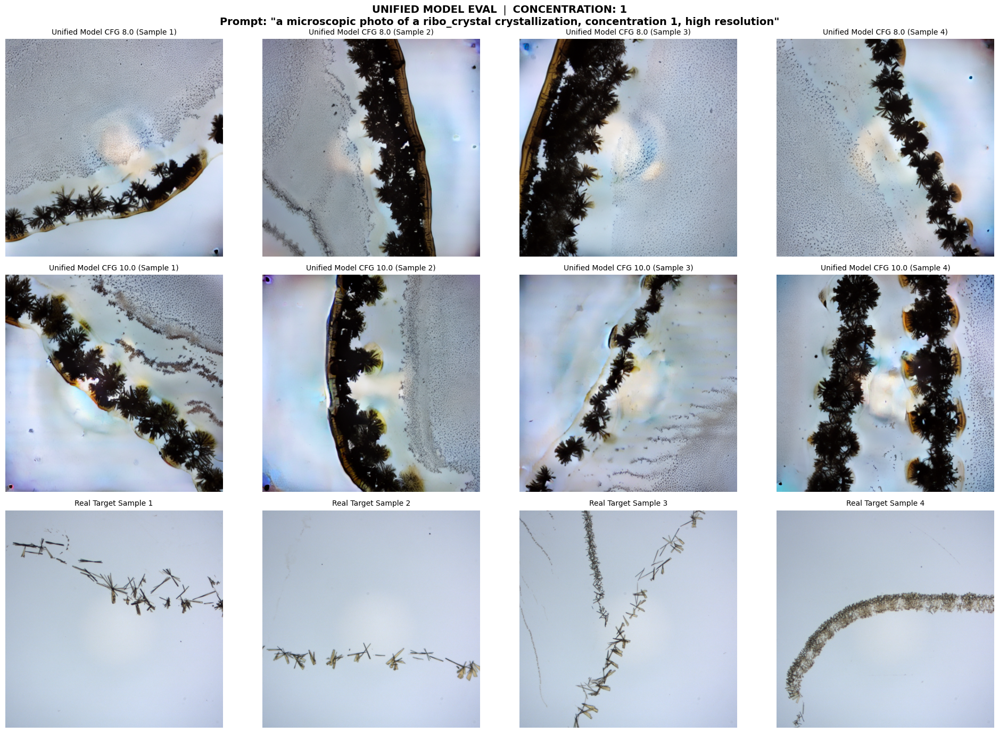

----------------------------------------------------------------------------------------------------
✨ Probing latent space for Concentration: [6]


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

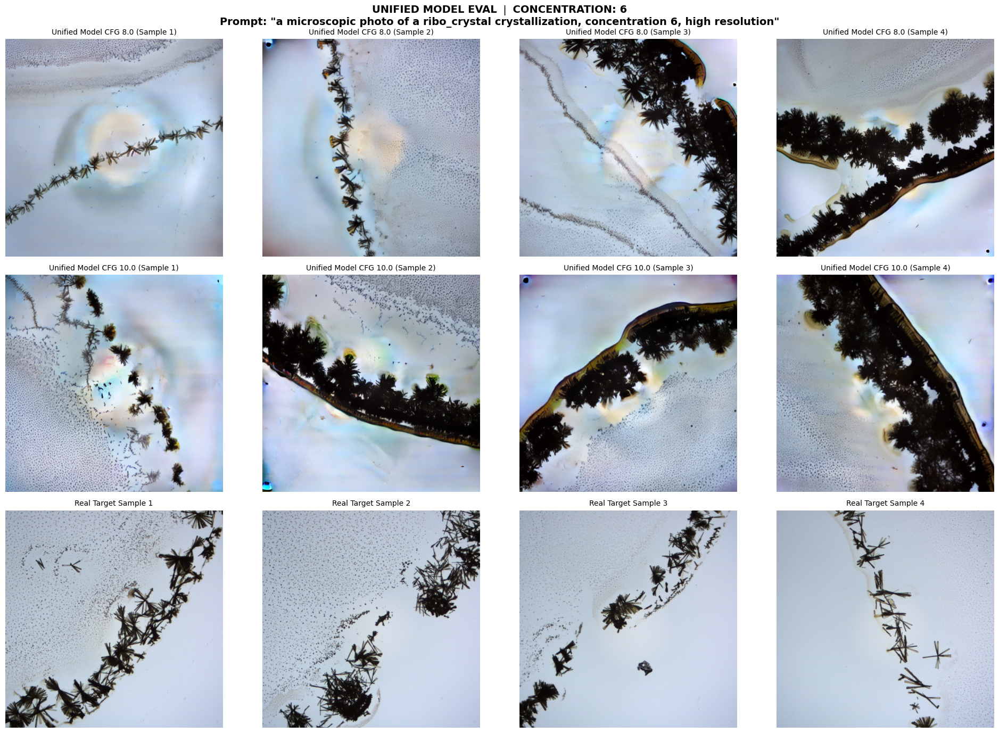

----------------------------------------------------------------------------------------------------
✨ Probing latent space for Concentration: [12.5]


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

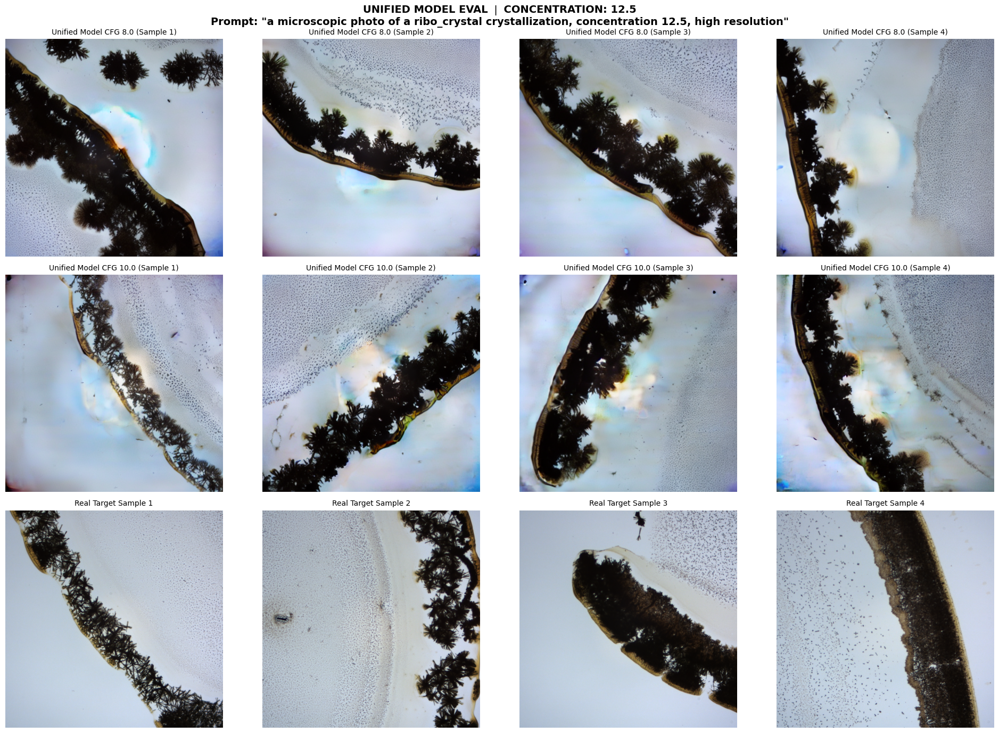

----------------------------------------------------------------------------------------------------
✨ Probing latent space for Concentration: [25]


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

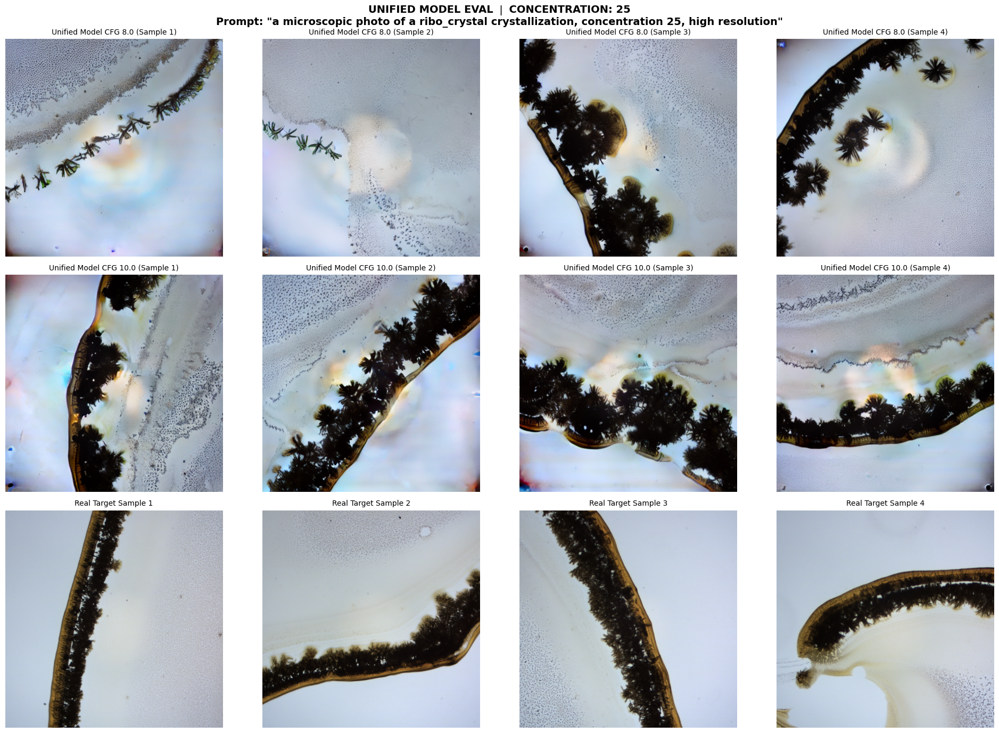

----------------------------------------------------------------------------------------------------

✅ Unified master model matrix evaluation sweep finished successfully!


In [9]:
import os
import random
import torch
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "./Riboflavin_NAOH_Water_Dilution"
UNIFIED_LORA_PATH = "./lora_riboflavin_unified_model"  # Path to your master unified model
N_SAMPLES = 4  # Number of horizontal images per row variation
# ---------------------

if not os.path.exists(SOURCE_DATA_DIR):
    raise FileNotFoundError(f"Missing source directory at {SOURCE_DATA_DIR}.")

if not os.path.exists(UNIFIED_LORA_PATH):
    raise FileNotFoundError(f"Missing unified LoRA weights folder at {UNIFIED_LORA_PATH}.")

# Target concentrations based on your clean folder setup
TARGET_CONCENTRATIONS = ["1", "6", "12.5", "25"]

# ==========================================
# 1. LOAD UNIFIED PIPELINE (OPTIMIZED ONCE)
# ==========================================
print(f"🔮 Loading Master Unified Model Weights from '{UNIFIED_LORA_PATH}'...")

# Using a single pipeline instance to minimize VRAM footprints
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", 
    torch_dtype=torch.float16
).to("cuda")

pipe.load_lora_weights(UNIFIED_LORA_PATH, weight_name="pytorch_lora_weights.safetensors")

# ==========================================
# 2. RUN COHORT-SPECIFIC GENERATION SWEEP
# ==========================================
print("\n🎬 Executing Concentration Sweep on the Unified Model...")

for conc in TARGET_CONCENTRATIONS:
    target_folder = os.path.join(SOURCE_DATA_DIR, conc)
    if not os.path.exists(target_folder):
        print(f"⚠️ Directory not found for concentration {conc}, skipping.")
        continue
        
    print(f"✨ Probing latent space for Concentration: [{conc}]")
    
    # Build updated text prompt matching your new structure without type modifiers
    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {conc}, high resolution"
    
    # 1. Fetch real lab ground-truths directly out of the subdirectory
    all_files = os.listdir(target_folder)
    bmp_files = [f for f in all_files if f.lower().endswith(".bmp")]
    
    real_samples = []
    if bmp_files:
        sampled_names = random.sample(bmp_files, min(N_SAMPLES, len(bmp_files)))
        real_samples = [os.path.join(target_folder, name) for name in sampled_names]
        
        # Duplicate list items if there are fewer images available than columns
        if len(real_samples) < N_SAMPLES:
            real_samples = (real_samples * N_SAMPLES)[:N_SAMPLES]

    # 2. Inference generation matching standard vs high structural guidance
    with torch.inference_mode():
        gen_standard = pipe(
            prompt, 
            num_images_per_prompt=N_SAMPLES, 
            num_inference_steps=30, 
            guidance_scale=8.0
        ).images

        gen_constrained = pipe(
            prompt, 
            num_images_per_prompt=N_SAMPLES, 
            num_inference_steps=30, 
            guidance_scale=10.0
        ).images

    # 3. Render 3-row grid block for this configuration intersection
    fig, axes = plt.subplots(3, N_SAMPLES, figsize=(5 * N_SAMPLES, 14))
    plt.suptitle(f"UNIFIED MODEL EVAL ❘ CONCENTRATION: {conc}\nPrompt: \"{prompt}\"", 
                 fontsize=14, weight='bold', y=0.98)

    for i in range(N_SAMPLES):
        # Row 0: Unified Model - Standard Guidance
        axes[0, i].imshow(gen_standard[i])
        axes[0, i].set_title(f"Unified Model CFG 8.0 (Sample {i+1})", fontsize=10)
        axes[0, i].axis('off')
        
        # Row 1: Unified Model - Higher Guidance Constraint
        axes[1, i].imshow(gen_constrained[i])
        axes[1, i].set_title(f"Unified Model CFG 10.0 (Sample {i+1})", fontsize=10)
        axes[1, i].axis('off')
        
        # Row 2: Real Lab Ground-Truths
        if real_samples and i < len(real_samples):
            img_path = real_samples[i]
            
            try:
                with Image.open(img_path) as real_img:
                    w, h = real_img.size
                    crop_size = 3000
                    actual_crop = min(crop_size, w, h)
                    
                    left = (w - actual_crop) // 2
                    top = (h - actual_crop) // 2
                    
                    cropped_img = real_img.crop((left, top, left + actual_crop, top + actual_crop))
                    axes[2, i].imshow(cropped_img, cmap='gray' if real_img.mode == 'L' else None)
                axes[2, i].set_title(f"Real Target Sample {i+1}", fontsize=10)
            except Exception as e:
                axes[2, i].text(0.5, 0.5, "Image Load Err", ha='center', va='center', color='red')
        else:
            axes[2, i].text(0.5, 0.5, "No Real Samples", ha='center', va='center', color='orange')
            
        axes[2, i].axis('off')

    # Clean layouts and display matrix block
    plt.subplots_adjust(hspace=0.25, wspace=0.1)
    plt.tight_layout()
    plt.show()
    print("-" * 100)

# Final VRAM Cleanup
del pipe
torch.cuda.empty_cache()

print("\n✅ Unified master model matrix evaluation sweep finished successfully!")

### multi-testing

🔮 Starting Feature-Matched Concentration Visual Audit...

🚀 Loading dedicated weights for [Concentration: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

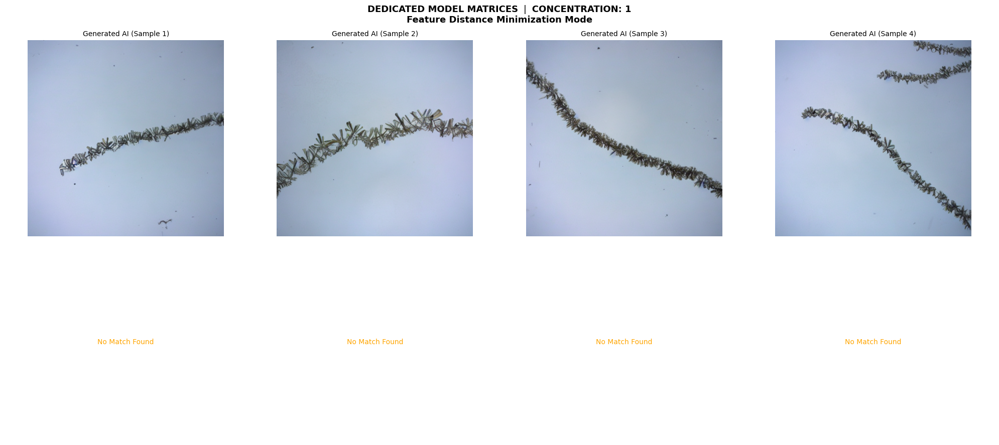

----------------------------------------------------------------------------------------------------

🚀 Loading dedicated weights for [Concentration: 6]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

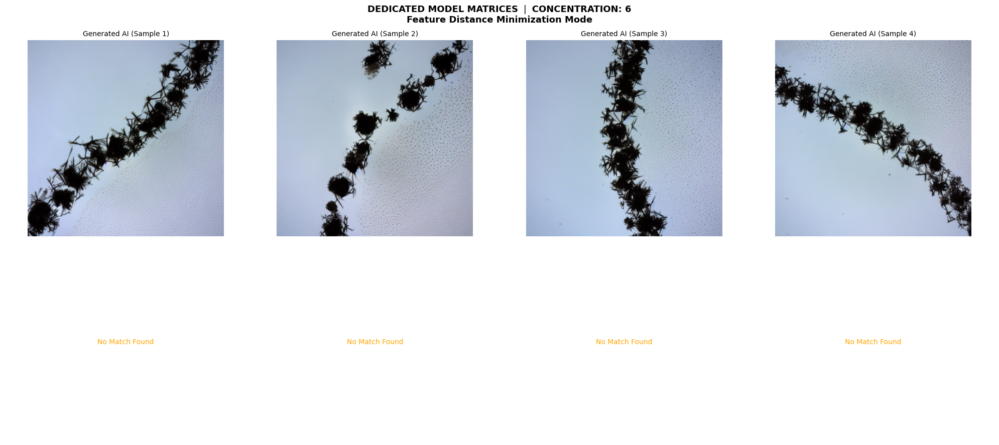

----------------------------------------------------------------------------------------------------

🚀 Loading dedicated weights for [Concentration: 12.5]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

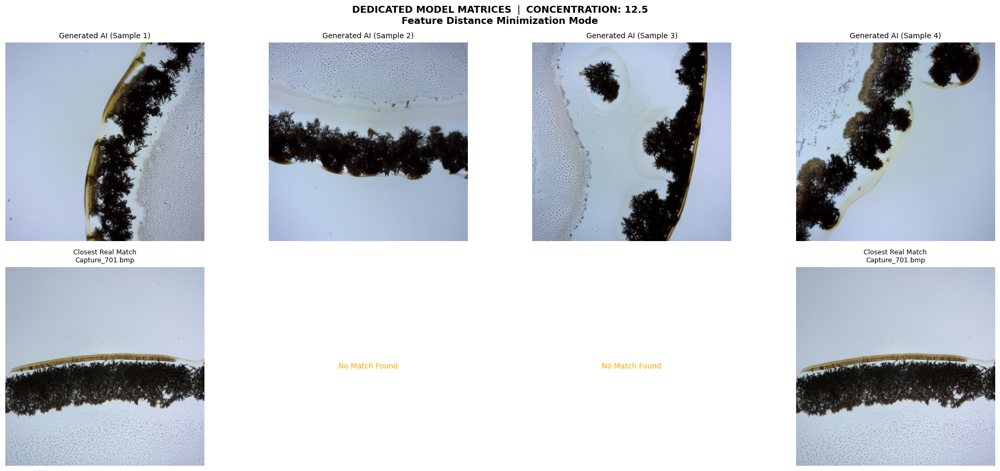

----------------------------------------------------------------------------------------------------

🚀 Loading dedicated weights for [Concentration: 25]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

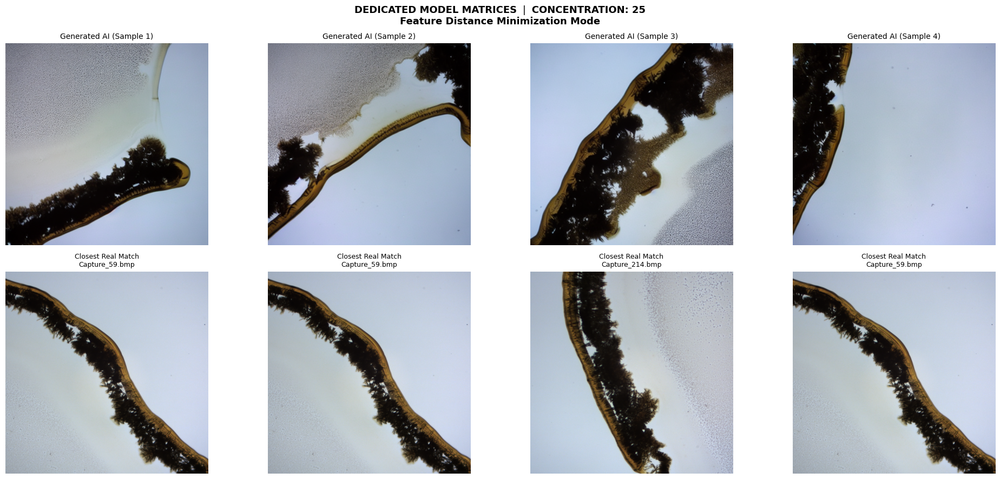

----------------------------------------------------------------------------------------------------

🚀 Loading dedicated weights for [Concentration: 50]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

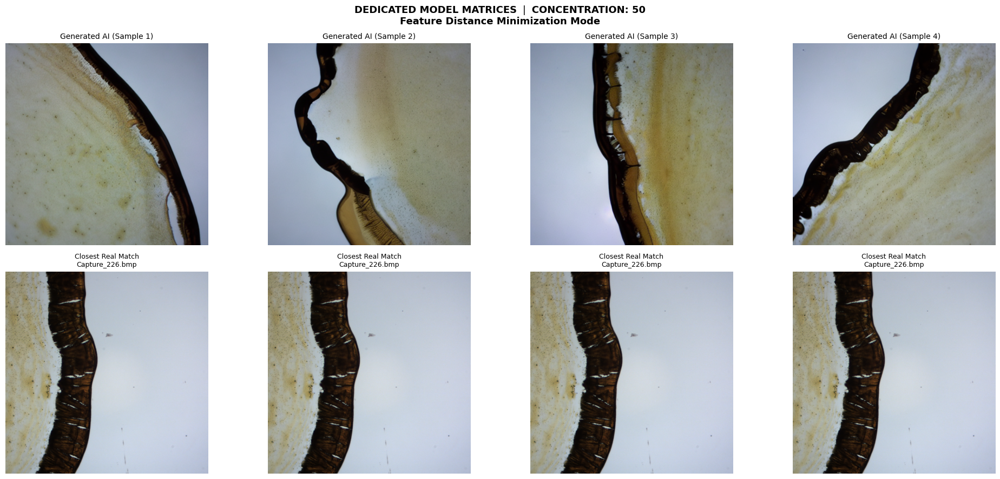

----------------------------------------------------------------------------------------------------

🚀 Loading dedicated weights for [Concentration: 100]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

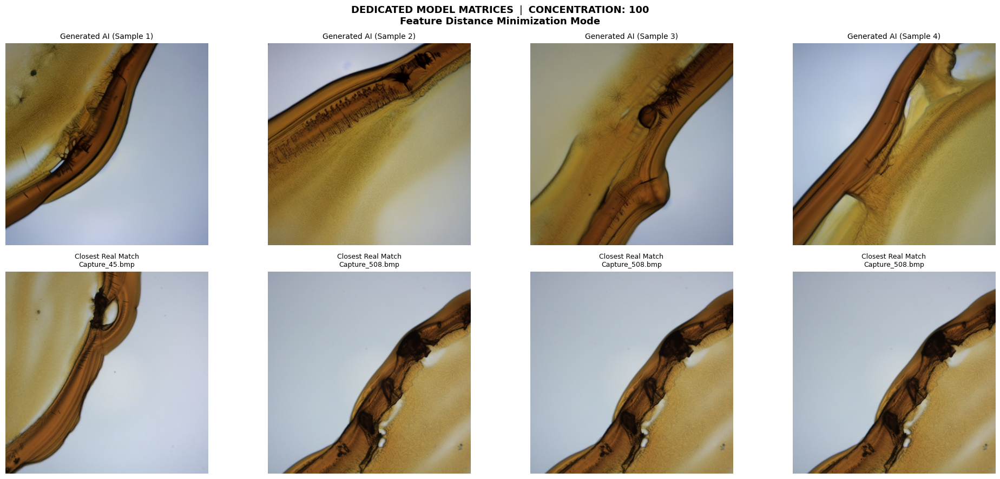

----------------------------------------------------------------------------------------------------

✅ Feature-matched evaluation sweep completed successfully!


In [47]:
import os
import random
import torch
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Feature extraction imports
import cv2
from skimage import measure
from skimage.morphology import skeletonize
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis
from scipy.ndimage import convolve, distance_transform_edt, generic_filter
from skimage.filters import gabor_kernel

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "./Riboflavin_NAOH_Water_Dilution/"
FEATURES_CSV = "riboflavin_features_new.csv"
N_SAMPLES = 4  # Number of horizontal variations per concentration row
THRES = 100
CORE_THRES = 50
# ---------------------

if not os.path.exists(SOURCE_DATA_DIR):
    raise FileNotFoundError(f"❌ Missing source root directory at {SOURCE_DATA_DIR}")
if not os.path.exists(FEATURES_CSV):
    raise FileNotFoundError(f"❌ Missing pre-computed features CSV at {FEATURES_CSV}")

TARGET_CONCENTRATIONS = ["1", "6", "12.5", "25", "50", "100"]

# =========================================================
# HELPER: RUNTIME FEATURE EXTRACTION FOR GENERATED IMAGES
# =========================================================
# Setup Gabor Kernels exactly matching your pipeline
gabor_kernels = []
for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    for frequency in [0.1, 0.3]:
        kernel = np.real(gabor_kernel(frequency, theta=theta))
        gabor_kernels.append(kernel)

def extract_features_from_pil(pil_img):
    """ Extracts feature vector from a PIL Image to match CSV layout """
    # Convert PIL to Grayscale OpenCV array
    img = np.array(pil_img.convert('L'))
    img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    
    imgLow = img < THRES
    imgHigh = img < CORE_THRES
    total_pixels = img.size
    
    area_fraction = np.sum(imgLow) / total_pixels
    edges = cv2.Canny(img, 50, 150)
    edge_density = np.sum(edges > 0) / total_pixels
    
    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    areas = [p.area for p in props] if props else [0]
    mean_cluster_area = np.mean(areas)
    ecc = [p.eccentricity for p in props] if props else [0]
    mean_eccentricity = np.mean(ecc)
    
    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_intensity = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_intensity = kurtosis(pixels_crystal) if len(pixels_crystal) else 0
    
    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    skel_uint8 = skel.astype(np.uint8)
    kernel_3x3 = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)
    skeleton_neighbors = neighbor_count * skel_uint8
    num_endpoints = np.sum(skeleton_neighbors == 1)
    num_branches = np.sum(skeleton_neighbors >= 3)
    
    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0
    
    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    
    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)
    
    def fractal_dimension(Z):
        Z = Z < THRES
        sizes = np.array([2, 4, 8, 16, 32])
        counts = []
        for size in sizes:
            resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))
            counts.append(np.sum(resized > 0))
        if len(counts) == 0 or np.sum(counts) == 0: return 0
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        return -coeffs[0]
        
    fractal_dim = fractal_dimension(img)
    
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1)
    fft_energy = np.mean(magnitude)
    
    feature_vector = [
        area_fraction, edge_density, num_clusters, mean_cluster_area, mean_eccentricity,
        mean_intensity, std_intensity, skew_intensity, kurt_intensity, skeleton_length,
        num_branches, num_endpoints, mean_thickness, max_thickness, contrast, energy,
        correlation, mean_local_std, std_local_std, fractal_dim, fft_energy
    ]
    
    for kernel in gabor_kernels:
        filtered = convolve(img.astype(float), kernel, mode='reflect')
        feature_vector.append(np.mean(filtered))
        feature_vector.append(np.std(filtered))
        feature_vector.append(np.mean(filtered ** 2))
        feature_vector.append(np.max(filtered))
        feature_vector.append(skew(filtered.ravel()))
        
    return np.array(feature_vector)


# Load database features and clean non-finite artifacts safely
df_base = pd.read_csv(FEATURES_CSV)
df_base.replace([np.inf, -np.inf], np.nan, inplace=True)

print("🔮 Starting Feature-Matched Concentration Visual Audit...")

for conc in TARGET_CONCENTRATIONS:
    target_folder = os.path.join(SOURCE_DATA_DIR, conc)
    lora_path = f"./lora_riboflavin_model_{conc}_new"
    
    if not os.path.exists(lora_path) or not os.path.exists(target_folder):
        print(f"⏩ Skipping Concentration: {conc} — Missing model directory or target data path.")
        continue

    # Filter base dataframe for this active label chunk
    target_float = float(conc)
    
    # Safely convert column to numeric (coercing bad entries to NaN), then filter
    df_base['label_numeric'] = pd.to_numeric(df_base['label'], errors='coerce')
    df_subset = df_base[np.isclose(df_base['label_numeric'], target_float)].copy()
    df_subset.drop(columns=['label_numeric'], inplace=True)

    if df_subset.empty:
        print(f"⏩ Skipping Concentration: {conc} — No rows found in feature CSV matching float value {target_float}.")
        continue
        
    # Drop rows containing NaNs in feature space
    feature_cols = df_subset.columns[2:]
    df_subset.dropna(subset=feature_cols, inplace=True)
    
    if df_subset.empty:
        print(f"⏩ Skipping Concentration: {conc} — Features dropped due to NaN metrics.")
        continue

    # Prepare standardization arrays to prevent scaling dominance biases
    base_features = df_subset[feature_cols].values
    feat_mean = np.mean(base_features, axis=0)
    feat_std = np.std(base_features, axis=0)
    feat_std[feat_std == 0] = 1e-6  # Prevent division by zero
    
    scaled_base = (base_features - feat_mean) / feat_std

    print(f"\n🚀 Loading dedicated weights for [Concentration: {conc}]...")
    pipe = StableDiffusionPipeline.from_pretrained(
        "runwayml/stable-diffusion-v1-5", 
        torch_dtype=torch.float16
    ).to("cuda")
    pipe.load_lora_weights(lora_path, weight_name="pytorch_lora_weights.safetensors")

    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {conc}, high resolution"

    with torch.inference_mode():
        gen_images = pipe(
            prompt, 
            num_images_per_prompt=N_SAMPLES, 
            num_inference_steps=30, 
            guidance_scale=8.0
        ).images

    # Match generated images to closest real samples
    matched_real_paths = []
    for gen_img in gen_images:
        try:
            gen_feat = extract_features_from_pil(gen_img)
            # Standardize using baseline limits
            scaled_gen = (gen_feat - feat_mean) / feat_std
            
            # Compute Euclidean metrics across the set
            distances = np.linalg.norm(scaled_base - scaled_gen, axis=1)
            closest_idx = np.argmin(distances)
            
            matched_filename = df_subset.iloc[closest_idx]['filename']
            matched_real_paths.append(os.path.join(target_folder, matched_filename))
        except Exception as e:
            matched_real_paths.append(None)

    # Render a 2-row audit matrix
    fig, axes = plt.subplots(2, N_SAMPLES, figsize=(5 * N_SAMPLES, 9))
    plt.suptitle(f"DEDICATED MODEL MATRICES ❘ CONCENTRATION: {conc}\nFeature Distance Minimization Mode", 
                 fontsize=13, weight='bold', y=0.98)

    for i in range(N_SAMPLES):
        # Row 0: AI Generation
        axes[0, i].imshow(gen_images[i])
        axes[0, i].set_title(f"Generated AI (Sample {i+1})", fontsize=10)
        axes[0, i].axis('off')
        
        # Row 1: Closest Real Target Image Match
        real_path = matched_real_paths[i]
        if real_path and os.path.exists(real_path):
            try:
                with Image.open(real_path) as real_img:
                    w, h = real_img.size
                    crop_size = 3000
                    actual_crop = min(crop_size, w, h)
                    
                    left = (w - actual_crop) // 2
                    top = (h - actual_crop) // 2
                    
                    cropped_img = real_img.crop((left, top, left + actual_crop, top + actual_crop))
                    axes[1, i].imshow(cropped_img, cmap='gray' if real_img.mode == 'L' else None)
                axes[1, i].set_title(f"Closest Real Match\n{os.path.basename(real_path)}", fontsize=9)
            except Exception as e:
                axes[1, i].text(0.5, 0.5, "Crop/Load Err", ha='center', va='center', color='red')
        else:
            axes[1, i].text(0.5, 0.5, "No Match Found", ha='center', va='center', color='orange')
            
        axes[1, i].axis('off')

    plt.subplots_adjust(hspace=0.2, wspace=0.1)
    plt.tight_layout()
    plt.show()
    
    # Cleanup memory
    del pipe
    torch.cuda.empty_cache()
    print("-" * 100)

print("\n✅ Feature-matched evaluation sweep completed successfully!")

### mutli type test

📖 Loading raw lab features dataset...
🔍 Scanning for active LoRA weight folders...
🔮 Screened out layout noise. Processing exactly 16 unique pipelines...

🚀 Loading pipeline weights dynamically: [Conc: 1 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


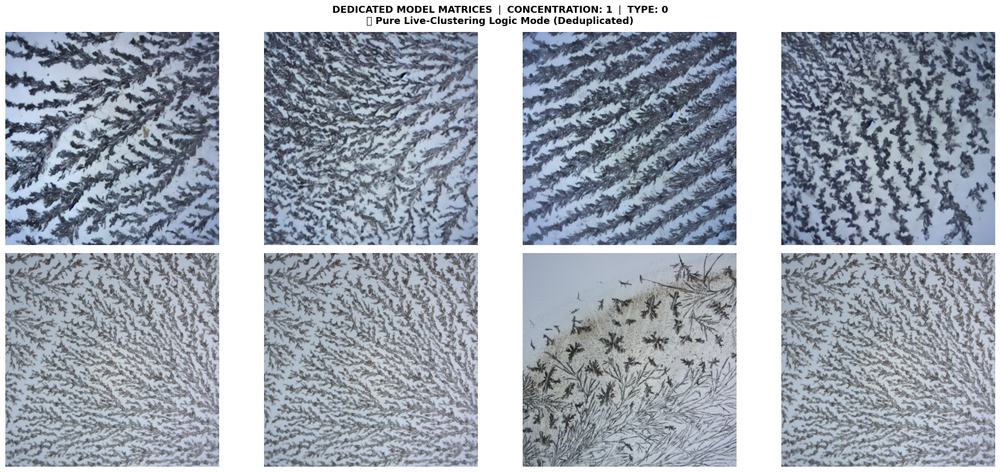

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 1 | Type: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


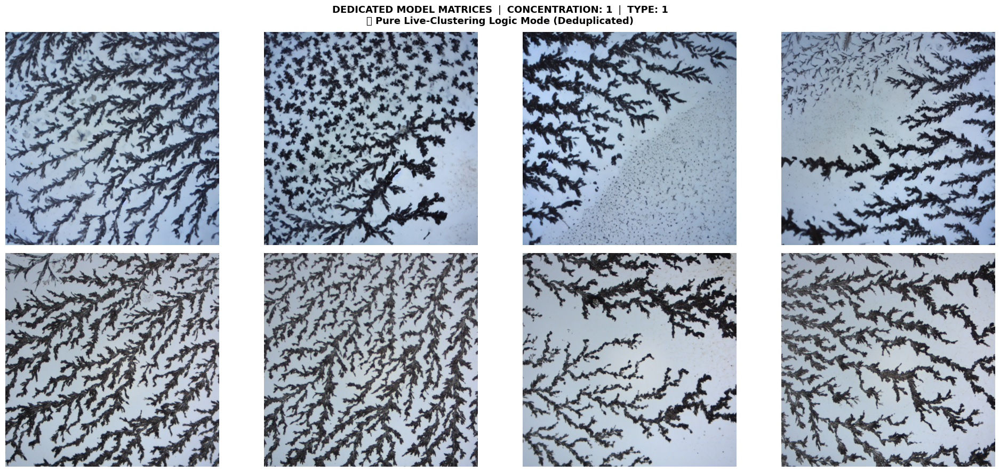

----------------------------------------------------------------------------------------------------
⏩ Skipping lora_riboflavin_model_1_type_2_new — No images found live for cluster index 2.

🚀 Loading pipeline weights dynamically: [Conc: 6 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


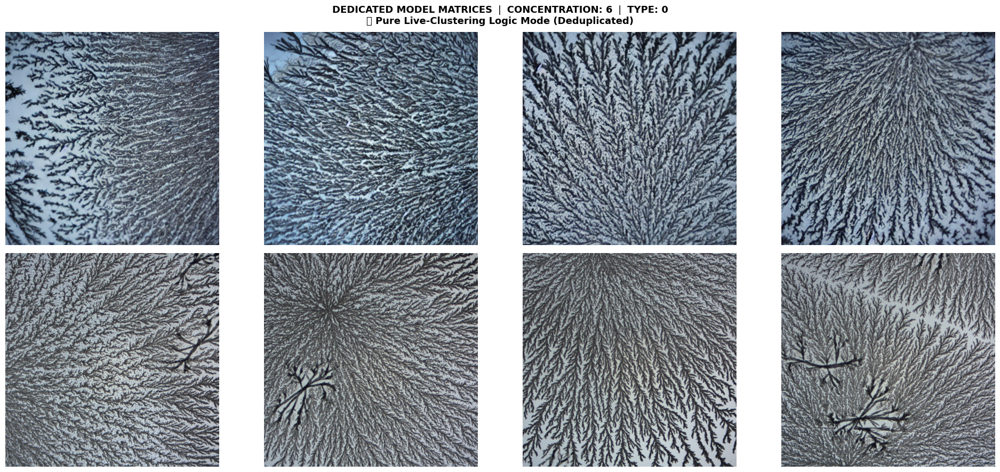

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 6 | Type: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


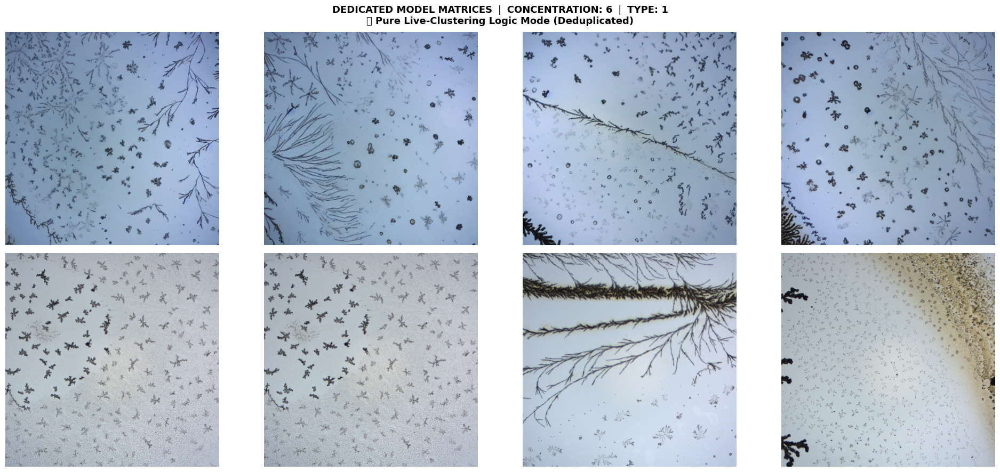

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 12.5 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


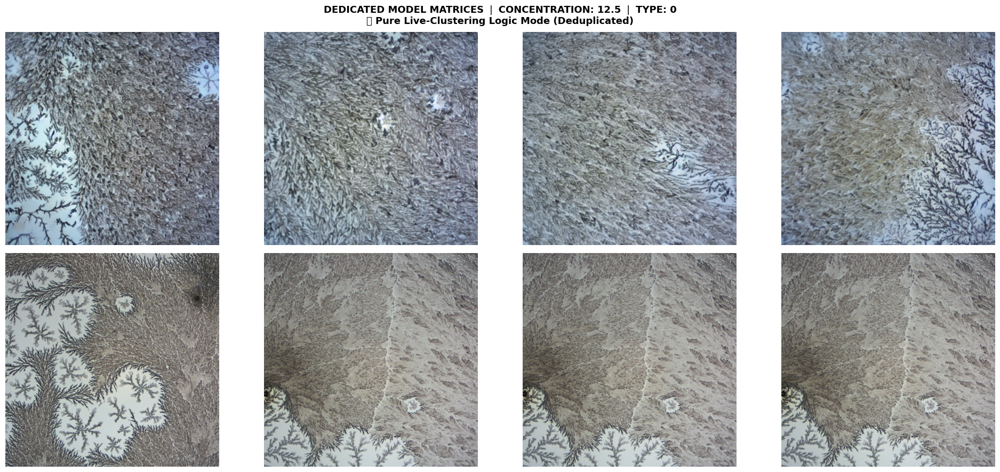

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 12.5 | Type: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


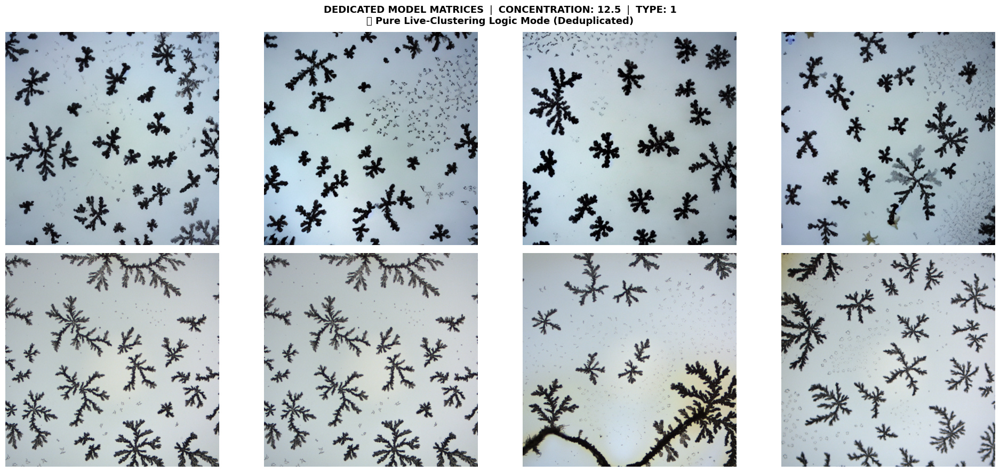

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 25 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


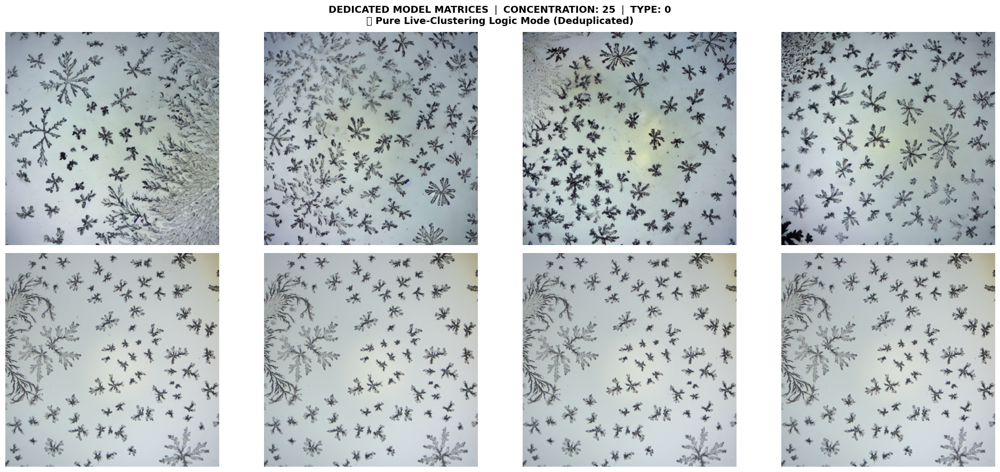

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 25 | Type: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


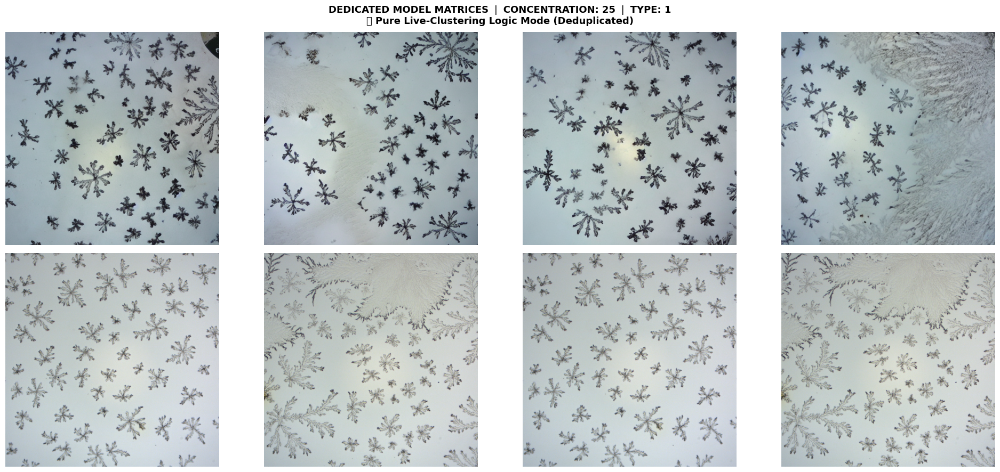

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 25 | Type: 2]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


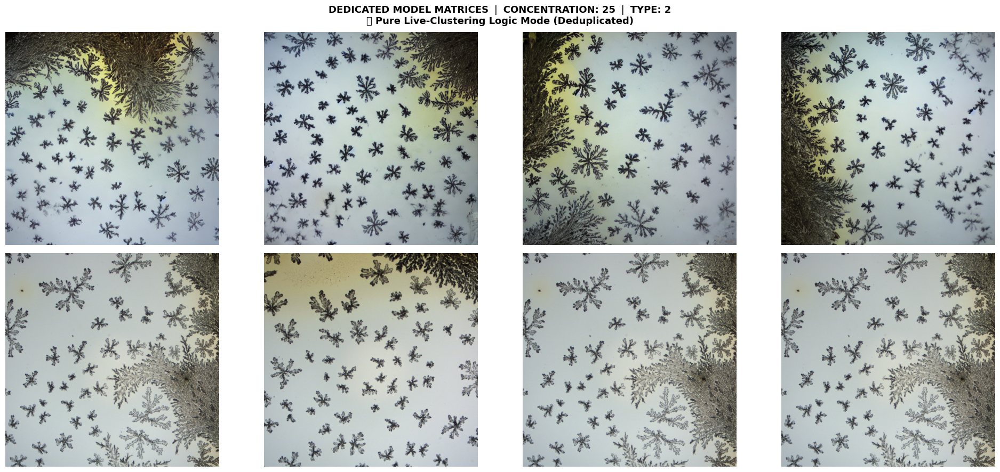

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 50 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


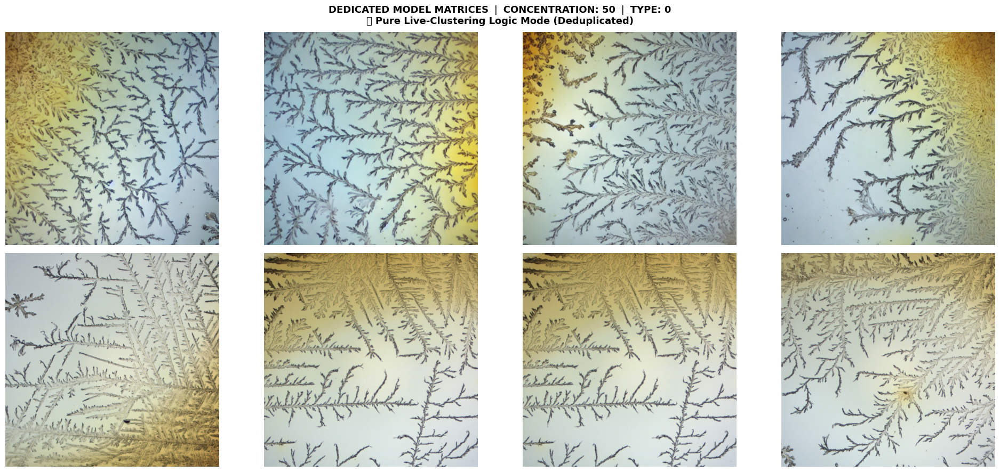

----------------------------------------------------------------------------------------------------

🚀 Loading pipeline weights dynamically: [Conc: 50 | Type: 1]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


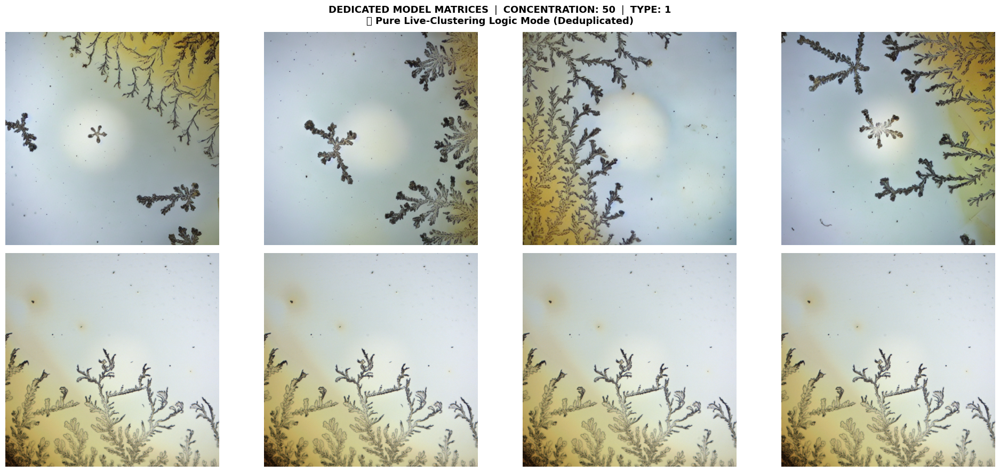

----------------------------------------------------------------------------------------------------
⏩ Skipping lora_riboflavin_model_50_type_2_new — No images found live for cluster index 2.

🚀 Loading pipeline weights dynamically: [Conc: 100 | Type: 0]...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_194/296118642.py:329: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


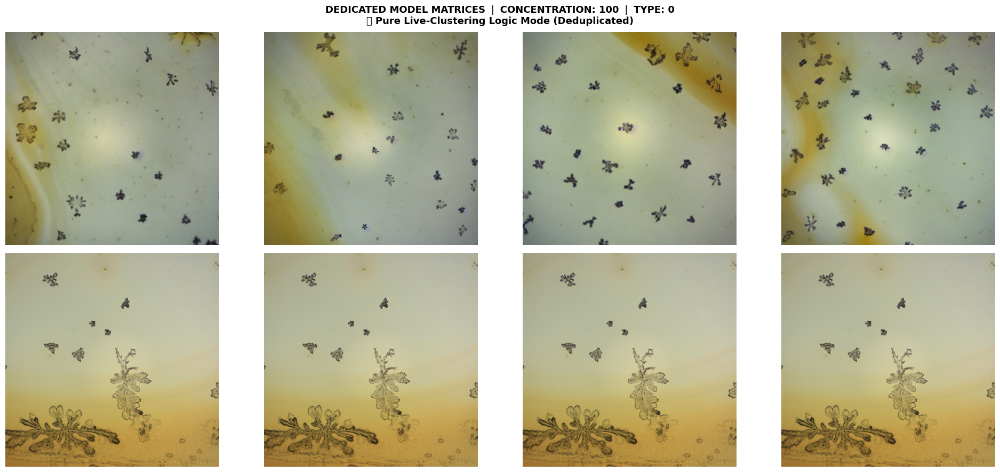

----------------------------------------------------------------------------------------------------
⏩ Skipping lora_riboflavin_model_100_type_1_new — No images found live for cluster index 1.
⏩ Skipping lora_riboflavin_model_100_type_2_new — No images found live for cluster index 2.

✅ Live-Clustering evaluation loop finished! Pairs successfully saved to: 'ai_gen_multi_type_resutls/'


In [6]:
import os
import re
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from diffusers import StableDiffusionPipeline

# Feature extraction imports
import cv2
from scipy.ndimage import convolve, distance_transform_edt, generic_filter
from scipy.stats import kurtosis, skew
from skimage import measure
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import gabor_kernel
from skimage.morphology import skeletonize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "./New_Riboflavin_Data/" 
FEATURES_CSV = "riboflavin_features_new.csv"  # The only index tracking file needed now
OUTPUT_DIR = "ai_gen_multi_type_resutls"       # Folder to save output pairs
N_SAMPLES = 4  # Number of horizontal variations per row
THRES = 100
CORE_THRES = 50
# ---------------------

if not os.path.exists(SOURCE_DATA_DIR):
    raise FileNotFoundError(f"❌ Missing source root directory at {SOURCE_DATA_DIR}")
if not os.path.exists(FEATURES_CSV):
    raise FileNotFoundError(f"❌ Missing original feature CSV at {FEATURES_CSV}")

# Ensure the output saving directory exists
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# HELPER: RUNTIME FEATURE EXTRACTION FOR IMAGES
# =========================================================
gabor_kernels = []
for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
    for frequency in [0.1, 0.3]:
        kernel = np.real(gabor_kernel(frequency, theta=theta))
        gabor_kernels.append(kernel)

def extract_features_from_pil(pil_img):
    img = np.array(pil_img.convert('L'))
    img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    
    imgLow = img < THRES
    imgHigh = img < CORE_THRES
    total_pixels = img.size
    
    area_fraction = np.sum(imgLow) / total_pixels
    edges = cv2.Canny(img, 50, 150)
    edge_density = np.sum(edges > 0) / total_pixels
    
    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    areas = [p.area for p in props] if props else [0]
    mean_cluster_area = np.mean(areas)
    ecc = [p.eccentricity for p in props] if props else [0]
    mean_eccentricity = np.mean(ecc)
    
    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_intensity = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_intensity = kurtosis(pixels_crystal) if len(pixels_crystal) else 0
    
    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    skel_uint8 = skel.astype(np.uint8)
    kernel_3x3 = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)
    skeleton_neighbors = neighbor_count * skel_uint8
    num_endpoints = np.sum(skeleton_neighbors == 1)
    num_branches = np.sum(skeleton_neighbors >= 3)
    
    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0
    
    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    
    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)
    
    def fractal_dimension(Z):
        Z = Z < THRES
        sizes = np.array([2, 4, 8, 16, 32])
        counts = []
        for size in sizes:
            resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))
            counts.append(np.sum(resized > 0))
        if len(counts) == 0 or np.sum(counts) == 0: return 0
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        return -coeffs[0]
        
    fractal_dim = fractal_dimension(img)
    
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1)
    fft_energy = np.mean(magnitude)
    
    feature_vector = [
        area_fraction, edge_density, num_clusters, mean_cluster_area, mean_eccentricity,
        mean_intensity, std_intensity, skew_intensity, kurt_intensity, skeleton_length,
        num_branches, num_endpoints, mean_thickness, max_thickness, contrast, energy,
        correlation, mean_local_std, std_local_std, fractal_dim, fft_energy
    ]
    
    for kernel in gabor_kernels:
        filtered = convolve(img.astype(float), kernel, mode='reflect')
        feature_vector.append(np.mean(filtered))
        feature_vector.append(np.std(filtered))
        feature_vector.append(np.mean(filtered ** 2))
        feature_vector.append(np.max(filtered))
        feature_vector.append(skew(filtered.ravel()))
        
    return feature_vector


# 1. Load and clean the master feature dataset
print("📖 Loading raw lab features dataset...")
df_master = pd.read_csv(FEATURES_CSV)
df_master.columns = df_master.columns.str.strip()
df_master['filename'] = df_master['filename'].str.strip()
df_master = df_master.dropna()
df_master['label'] = df_master['label'].astype(float)

# Isolate feature column keys matching your vector geometry
non_feature_cols = ['filename', 'label', 'sub_morphology_cluster']
feature_names = [col for col in df_master.columns if col not in non_feature_cols]

# 2. Scan and Deduplicate Active LoRA Pipeline Runs
print("🔍 Scanning for active LoRA weight folders...")
raw_runs = []
for directory in os.listdir("."):
    match = re.match(r"^lora_riboflavin_model_([0-9.]+)_type_(\d+)_new$", directory)
    if match:
        conc_raw = match.group(1)
        type_val = int(match.group(2))
        conc_float = float(conc_raw)
        
        # Standardize concentration naming string
        if conc_float in [6.5, 6.50, 6.25]:
            folder_conc_str = "6.25"
        else:
            folder_conc_str = str(int(conc_float)) if conc_float.is_integer() else str(conc_float)
            
        composite_key = f"{folder_conc_str}_type_{type_val}"
        folder_path = os.path.join(".", directory)
        mod_time = os.path.getmtime(folder_path)
        
        raw_runs.append({
            "folder_name": directory,
            "conc_str": folder_conc_str,
            "conc_float": conc_float,
            "type": type_val,
            "composite_key": composite_key,
            "mod_time": mod_time,
            "sort_key": (conc_float, type_val)
        })

# Enforce clean deduplication (keeps only the absolute latest folder run per profile)
best_runs = {}
for run in raw_runs:
    ckey = run["composite_key"]
    if ckey not in best_runs:
        best_runs[ckey] = run
    else:
        if run["mod_time"] > best_runs[ckey]["mod_time"]:
            best_runs[ckey] = run

active_runs = sorted(best_runs.values(), key=lambda x: x['sort_key'])
print(f"🔮 Screened out layout noise. Processing exactly {len(active_runs)} unique pipelines...")

# 3. Process each pipeline live
for run in active_runs:
    conc_str = run["conc_str"]
    conc_float = run["conc_float"]
    morph_type = run["type"]
    lora_path = os.path.join(".", run["folder_name"])
    
    target_folder = os.path.join(SOURCE_DATA_DIR, conc_str)
    if not os.path.exists(target_folder):
        print(f"⏩ Skipping {run['folder_name']} — Image folder '{target_folder}' doesn't exist.")
        continue

    # --- LIVE DYNAMIC CLUSTERING FACTORY ---
    # Isolate all dataset entries matching this concentration float
    df_subset = df_master[df_master['label'] == conc_float].copy()
    
    if len(df_subset) < 4:
        print(f"⏩ Skipping {run['folder_name']} — Insufficient real data for clustering ({len(df_subset)} rows).")
        continue
        
    X = df_subset[feature_names].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Run dynamic optimization loops matching your baseline script
    best_k = 1
    best_score = -1
    for k in [2, 3]:
        if len(X_scaled) > k:
            km = KMeans(n_clusters=k, random_state=42, n_init=10)
            labels = km.fit_predict(X_scaled)
            score = silhouette_score(X_scaled, labels)
            if score > best_score:
                best_score = score
                best_k = k
                
    # Assign cluster identities live in memory
    df_subset["sub_morphology_cluster"] = 0
    if best_k > 1 and best_score > 0.22:
        final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
        df_subset["sub_morphology_cluster"] = final_km.fit_predict(X_scaled)
        
    # Isolate the precise target cluster group requested by this specific model run
    df_cluster = df_subset[df_subset["sub_morphology_cluster"] == morph_type].copy()
    if df_cluster.empty:
        print(f"⏩ Skipping {run['folder_name']} — No images found live for cluster index {morph_type}.")
        continue
        
    # Calculate live target slice stats (Means and Variances)
    feat_mean = df_cluster[feature_names].mean().values
    feat_std = df_cluster[feature_names].std().values
    
    # Handle zero-variance safety buffers cleanly
    feat_std = np.where(pd.isna(feat_std) | (feat_std == 0), 1e-5, feat_std)
    
    # Pre-calculate Z-scored spatial layout profiles for the real reference vectors
    base_features = df_cluster[feature_names].values
    scaled_base = (base_features - feat_mean) / feat_std
    # ----------------------------------------

    print(f"\n🚀 Loading pipeline weights dynamically: [Conc: {conc_str} | Type: {morph_type}]...")
    try:
        pipe = StableDiffusionPipeline.from_pretrained(
            "runwayml/stable-diffusion-v1-5", 
            torch_dtype=torch.float16
        ).to("cuda")
        pipe.load_lora_weights(lora_path, weight_name="pytorch_lora_weights.safetensors")
    except Exception as e:
        print(f"❌ Failed loading LoRA weights. Error: {e}")
        if 'pipe' in locals(): del pipe
        torch.cuda.empty_cache()
        continue

    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {conc_str}, type_{morph_type} morphology, high resolution"

    with torch.inference_mode():
        gen_images = pipe(
            prompt, 
            num_images_per_prompt=N_SAMPLES, 
            num_inference_steps=30, 
            guidance_scale=8.0
        ).images

    # Calculate real-time vector matching distances
    matched_real_paths = []
    for gen_img in gen_images:
        try:
            gen_feat = np.array(extract_features_from_pil(gen_img))
            scaled_gen = (gen_feat - feat_mean) / feat_std
            
            distances = np.linalg.norm(scaled_base - scaled_gen, axis=1)
            closest_idx = np.argmin(distances)
            
            matched_filename = df_cluster.iloc[closest_idx]['filename']
            matched_real_paths.append(os.path.join(target_folder, matched_filename))
        except Exception:
            matched_real_paths.append(None)

    # Render Audit Visualization Matrix & Save Pair Files
    fig, axes = plt.subplots(2, N_SAMPLES, figsize=(5 * N_SAMPLES, 9))
    plt.suptitle(f"DEDICATED MODEL MATRICES ❘ CONCENTRATION: {conc_str} ❘ TYPE: {morph_type}\n🔴 Pure Live-Clustering Logic Mode (Deduplicated)", 
                 fontsize=13, weight='bold', y=0.98)

    for i in range(N_SAMPLES):
        pair_num = i + 1
        
        # 1. Save and Plot: AI Generation
        ai_img = gen_images[i]
        axes[0, i].imshow(ai_img)
        axes[0, i].axis('off')
        
        ai_filename = f"{conc_str}_{morph_type}_{pair_num}_ai.png"
        ai_img.save(os.path.join(OUTPUT_DIR, ai_filename))
        
        # 2. Save Original and Plot Cropped: Target Real Image Match
        real_path = matched_real_paths[i]
        
        if real_path and os.path.exists(real_path):
            try:
                with Image.open(real_path) as real_img:
                    # Save the pristine, original uncropped image
                    real_filename = f"{conc_str}_{morph_type}_{pair_num}_real.png"
                    real_img.save(os.path.join(OUTPUT_DIR, real_filename))
                    
                    # Crop ONLY for the matplotlib grid display so the aspect ratio looks clean
                    w, h = real_img.size
                    crop_size = 3000
                    actual_crop = min(crop_size, w, h)
                    
                    left = (w - actual_crop) // 2
                    top = (h - actual_crop) // 2
                    
                    cropped_display_img = real_img.crop((left, top, left + actual_crop, top + actual_crop))
                    axes[1, i].imshow(cropped_display_img, cmap='gray' if real_img.mode == 'L' else None)
            except Exception as e:
                axes[1, i].text(0.5, 0.5, "Load Err", ha='center', va='center', color='red')
        else:
            axes[1, i].text(0.5, 0.5, "No Match Found\nIn Live Cluster", ha='center', va='center', color='orange')
            
        axes[1, i].axis('off')

    plt.subplots_adjust(hspace=0.2, wspace=0.1)
    plt.tight_layout()
    plt.show()
    
    # Clean step memory footprints
    del pipe
    torch.cuda.empty_cache()
    print("-" * 100)

print(f"\n✅ Live-Clustering evaluation loop finished! Pairs successfully saved to: '{OUTPUT_DIR}/'")

### Rest of tests

In [ ]:
# ==============================================================================
# INTERACTIVE 3D/2D T-SNE EVALUATION MANIFOLD CELL (PLOTLY UPDATE)
# ==============================================================================

import os
import numpy as np
import pandas as pd
import cv2
import torch
from tqdm import tqdm
from diffusers import StableDiffusionPipeline
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Interactive Plotly Dependencies
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# Structural Topology Analysis Dependencies
from skimage import measure
from skimage.morphology import skeletonize
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis
from scipy.ndimage import generic_filter, distance_transform_edt, convolve

# --- CONFIGURATION ---
FEATURES_CSV_PATH = "riboflavin_features_NAOH.csv"
LORA_DIR_BASE = "./"                            # Folder where your lora_riboflavin_model_X_new folders live
TARGET_CONCENTRATIONS = ["1", "6", "12.5", "25", "50", "100"]
N_SIMULATIONS_PER_CONC = 500                   # Total generated dots per class for meaningful cluster comparisons
# ---------------------

def extract_synthetic_features(img_np):
    """
    Extracts 21 distinct morphology, texture, and statistical metrics 
    from a grayscale image matrix to match pre-calculated CSV profiles.
    """
    img = cv2.resize(img_np, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    THRES, CORE_THRES, total_pixels = 100, 50, img.size
    imgLow, imgHigh = img < THRES, img < CORE_THRES
    
    # Area & Edge Densities
    area_fraction = np.sum(imgLow) / total_pixels
    edge_density = np.sum(cv2.Canny(img, 50, 150) > 0) / total_pixels
    
    # Connected Component Clusters
    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    mean_cluster_area = np.mean([p.area for p in props]) if props else 0
    mean_eccentricity = np.mean([p.eccentricity for p in props]) if props else 0
    
    # Pixel Intensities
    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_val = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_val = kurtosis(pixels_crystal) if len(pixels_crystal) else 0
    
    # Thinning Skeleton Topology
    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    kernel_3x3 = np.array([[1,1,1], [1,0,1], [1,1,1]], dtype=np.uint8)
    neighbor_count = convolve(skel.astype(np.uint8), kernel_3x3, mode='constant', cval=0) * skel
    num_endpoints = np.sum(neighbor_count == 1)
    num_branches = np.sum(neighbor_count >= 3)
    
    # Distance Transform Thickness Maps
    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0
    
    # GLCM Textures
    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0,0]
    energy = graycoprops(glcm, 'energy')[0,0]
    correlation = graycoprops(glcm, 'correlation')[0,0]
    
    # Local Texture
    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)
    
    # Fractal Box Counts
    def fractal_dimension(Z):
        Z = Z < THRES
        sizes = np.array([2, 4, 8, 16, 32])
        counts = [np.sum(cv2.resize(Z.astype(np.uint8), (Z.shape[1]//s, Z.shape[0]//s)) > 0) for s in sizes]
        return -np.polyfit(np.log(sizes), np.log(counts), 1)[0] if np.sum(counts) > 0 else 0
    fractal_dim = fractal_dimension(img)
    
    # Fourier Frequency Domain
    fft_energy = np.mean(np.log(np.abs(np.fft.fftshift(np.fft.fft2(img))) + 1))
    
    return [area_fraction, edge_density, num_clusters, mean_cluster_area, 
            mean_eccentricity, mean_intensity, std_intensity, skew_val, kurt_val,
            skeleton_length, num_branches, num_endpoints, mean_thickness, max_thickness, 
            contrast, energy, correlation, mean_local_std, std_local_std, fractal_dim, fft_energy]


# ==========================================
# 1. COMPILE DATA MATRICES
# ==========================================
print("📖 Parsing pre-extracted lab crystal profiles...")
df_real = pd.read_csv(FEATURES_CSV_PATH)
df_real.columns = df_real.columns.str.strip()
df_real = df_real.dropna()

tracking_cols = [
    "area_fraction", "edge_density", "num_clusters", "mean_cluster_area", 
    "mean_eccentricity", "mean_intensity", "std_intensity", "skew", "kurtosis",
    "skeleton_length", "skeleton_branches", "skeleton_endpoints", 
    "mean_thickness", "max_thickness", "contrast", "energy", "correlation", 
    "mean_local_std", "std_local_std", "fractal_dim", "fft_energy"
]
active_cols = [col for col in tracking_cols if col in df_real.columns]

df_real['concentration_str'] = df_real['label'].apply(lambda x: f"{x:g}")
df_real = df_real[df_real['concentration_str'].isin(TARGET_CONCENTRATIONS)]

master_features = []
master_labels = []
master_origin = [] 

for _, row in df_real.iterrows():
    master_features.append([row[col] for col in active_cols])
    master_labels.append(row['concentration_str'])
    master_origin.append('Real')

print("🔮 Commencing feature tracking extractions across latent checkpoints...")
for conc in TARGET_CONCENTRATIONS:
    lora_path = os.path.join(LORA_DIR_BASE, f"lora_riboflavin_model_{conc}_new")
    if not os.path.exists(lora_path):
        print(f"⏩ Model {lora_path} missing. Skipping.")
        continue
        
    pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
    pipe.load_lora_weights(lora_path, weight_name="pytorch_lora_weights.safetensors")
    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {conc}, high resolution"
    
    with torch.inference_mode():
        for _ in tqdm(range(N_SIMULATIONS_PER_CONC), desc=f"   Simulating Conc {conc}"):
            gen_image = pipe(prompt, num_inference_steps=30, guidance_scale=9.0).images[0]
            gray_gen = cv2.cvtColor(np.array(gen_image), cv2.COLOR_RGB2GRAY)
            feats = extract_synthetic_features(gray_gen)
            
            aligned_feats = [feats[tracking_cols.index(col)] for col in active_cols]
            master_features.append(aligned_feats)
            master_labels.append(conc)
            master_origin.append('AI')
            
    del pipe
    torch.cuda.empty_cache()


# ==========================================
# 2. RUN MATHEMATICAL PROJECTIONS
# ==========================================
X_all = np.array(master_features)
y_labels = np.array(master_labels)
y_origin = np.array(master_origin)

X_all[np.isinf(X_all)] = np.nan
nan_mask = np.isnan(X_all).any(axis=1)
nan_count = np.sum(nan_mask)

if nan_count > 0:
    print(f"⚠️ Flagged {nan_count} invalid feature rows containing NaNs/Infs. Purging from projection matrix...")
    X_all = X_all[~nan_mask]
    y_labels = y_labels[~nan_mask]
    y_origin = y_origin[~nan_mask]

if X_all.size == 0:
    raise ValueError("❌ Fatal: All extracted rows contained NaNs.")

X_scaled = StandardScaler().fit_transform(X_all)

print(f"📊 Calculating global 3D t-SNE manifold topology coordinates...")
tsne = TSNE(
    n_components=3, 
    perplexity=30, 
    random_state=42, 
    init='random', 
    learning_rate='auto', 
    max_iter=1000
)
X_projected = tsne.fit_transform(X_scaled)

# Store results back into a clean dataframe for Plotly parsing
df_plot = pd.DataFrame(X_projected, columns=['tSNE_1', 'tSNE_2', 'tSNE_3'])
df_plot['Concentration'] = y_labels
df_plot['Domain'] = y_origin
df_plot['Combined_Key'] = df_plot['Domain'] + " - " + df_plot['Concentration'] + " ppm"


# ==========================================
# 3. INTERACTIVE PLOTLY SUBPLOTS MATRIX
# ==========================================
print("🎨 Building interactive dashboard canvas...")

# Construct an explicit grid layout: 1 Row, 2 Columns
# Col 1 receives the 3D Scatter setup, Col 2 receives standard 2D projection
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scene"}, {"type": "xy"}]],
    subplot_titles=(
        "<b>Interactive 3D Domain Overlap</b><br><sup>Click & Drag to Rotate Canvas</sup>", 
        "<b>Top-Down Structural View</b><br><sup>Orthogonal View (t-SNE 1 vs t-SNE 2)</sup>"
    ),
    horizontal_spacing=0.08
)

unique_concs = sorted(list(set(y_labels)), key=lambda x: float(x))
# Discrete custom color hex map matching your qualitative palette
colors = px.colors.qualitative.Bold[:len(unique_concs)]
color_map = dict(zip(unique_concs, colors))

# Markers mapped dynamically by Domain Origin: Circles for Real, Triangles for AI
symbol_3d_map = {'Real': 'circle', 'AI': 'diamond'}
symbol_2d_map = {'Real': 'circle', 'AI': 'diamond-open'}

for label in unique_concs:
    for domain in ['Real', 'AI']:
        mask = (df_plot['Concentration'] == label) & (df_plot['Domain'] == domain)
        sub_df = df_plot[mask]
        
        if len(sub_df) == 0:
            continue
            
        legend_group = f"group_{label}_{domain}"
        opacity = 0.4 if domain == 'Real' else 0.85
        
        # --- ADD TO INTERACTIVE 3D PANEL (LEFT) ---
        fig.add_trace(
            go.Scatter3d(
                x=sub_df['tSNE_1'], y=sub_df['tSNE_2'], z=sub_df['tSNE_3'],
                mode='markers',
                name=f"{domain} ({label} ppm)",
                legendgroup=legend_group,
                marker=dict(
                    size=4.5 if domain == 'Real' else 6,
                    color=color_map[label],
                    symbol=symbol_3d_map[domain],
                    opacity=opacity,
                    line=dict(color='black', width=0.5 if domain == 'Real' else 1)
                ),
                text=[f"Domain: {domain}<br>Conc: {label} ppm"] * len(sub_df),
                hoverinfo='text'
            ),
            row=1, col=1
        )
        
        # --- ADD TO TOP-DOWN 2D PANEL (RIGHT) ---
        fig.add_trace(
            go.Scatter(
                x=sub_df['tSNE_1'], y=sub_df['tSNE_2'],
                mode='markers',
                name=f"{domain} ({label} ppm)",
                legendgroup=legend_group,
                showlegend=False, # Link tracking triggers directly to the left panel controls
                marker=dict(
                    size=6 if domain == 'Real' else 8,
                    color=color_map[label],
                    symbol=symbol_2d_map[domain],
                    opacity=opacity
                ),
                text=[f"Domain: {domain}<br>Conc: {label} ppm"] * len(sub_df),
                hoverinfo='text'
            ),
            row=1, col=2
        )

# Update layout configurations globally
fig.update_layout(
    title_text="<b>Riboflavin Manifold Topology Alignment Dashboard</b>",
    title_font_size=20,
    width=1400,
    height=700,
    template="plotly_white",
    legend=dict(
        title_text="<b>Domain Guide</b>",
        yanchor="top", y=0.9,
        xanchor="left", x=1.02,
        font=dict(size=11)
    )
)

# Refine 3D Spatial Geometry Options
fig.update_scenes(
    xaxis_title='t-SNE 1',
    yaxis_title='t-SNE 2',
    zaxis_title='t-SNE 3',
    camera=dict(
        eye=dict(x=1.5, y=1.5, z=1.2) # Elegant default perspective angle
    ),
    row=1, col=1
)

# Refine 2D Subplot Orthogonal Axes
fig.update_xaxes(title_text="t-SNE Component 1", row=1, col=2)
fig.update_yaxes(title_text="t-SNE Component 2", row=1, col=2)

# Display dashboard frame
fig.show()

In [24]:
import plotly.io as pio
pio.renderers.default = "iframe" # Renders the plot inside a clean isolated sandbox frame
fig.show()

In [52]:
# ==============================================================================
# AUDIT CELL: CONSTRAINED VS UNCONSTRAINED STATISTICAL SIGNIFICANCE RUNNER
# ==============================================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import cv2
from tqdm import tqdm
from diffusers import StableDiffusionPipeline
from skimage import measure
from skimage.morphology import skeletonize
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis, ttest_1samp, ttest_ind
from scipy.ndimage import distance_transform_edt, convolve, generic_filter

# --- CONFIGURATION ---
FEATURES_CSV_PATH = "riboflavin_features_NAOH.csv"  # Target your pre-extracted features file
N_SIMULATIONS = 100                                 # Number of generated samples per model for stable stats
# --------------------------

print("📖 Parsing pre-extracted lab crystal profiles...")
if not os.path.exists(FEATURES_CSV_PATH):
    raise FileNotFoundError(f"Missing master feature profile map at '{FEATURES_CSV_PATH}'.")

df_real = pd.read_csv(FEATURES_CSV_PATH)
df_real.columns = df_real.columns.str.strip()
df_real = df_real.dropna()
df_real['label'] = df_real['label'].astype(float)

numeric_cols = df_real.select_dtypes(include=[np.number]).columns
real_stats = df_real[numeric_cols].groupby(['label']).agg(['mean', 'std'])

tracking_cols = [
    "area_fraction", "edge_density", "num_clusters", "mean_cluster_area", 
    "mean_eccentricity", "mean_intensity", "std_intensity", "skew", "kurtosis",
    "skeleton_length", "skeleton_branches", "skeleton_endpoints", 
    "mean_thickness", "max_thickness", "contrast", "energy", "correlation", 
    "mean_local_std", "std_local_std", "fractal_dim", "fft_energy"
]
feature_indices = {col: idx for idx, col in enumerate(tracking_cols)}
active_tracking_cols = [col for col in tracking_cols if col in df_real.columns]

def extract_synthetic_features(img_np):
    img = cv2.resize(img_np, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    THRES = 100
    CORE_THRES = 50
    total_pixels = img.size

    imgLow = img < THRES
    imgHigh = img < CORE_THRES

    area_fraction = np.sum(imgLow) / total_pixels
    edges = cv2.Canny(img, 50, 150)
    edge_density = np.sum(edges > 0) / total_pixels

    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    areas = [p.area for p in props] if props else [0]
    mean_cluster_area = np.mean(areas)
    ecc = [p.eccentricity for p in props] if props else [0]
    mean_eccentricity = np.mean(ecc)

    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_val = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_val = kurtosis(pixels_crystal) if len(pixels_crystal) else 0

    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    skel_uint8 = skel.astype(np.uint8)
    kernel_3x3 = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)
    skeleton_neighbors = neighbor_count * skel_uint8
    num_endpoints = np.sum(skeleton_neighbors == 1)
    num_branches = np.sum(skeleton_neighbors >= 3)

    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0

    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)

    def fractal_dimension(Z):
        Z = Z < THRES
        sizes = np.array([2, 4, 8, 16, 32])
        counts = []
        for size in sizes:
            resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))
            counts.append(np.sum(resized > 0))
        if len(counts) == 0 or np.sum(counts) == 0:
            return 0
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        return -coeffs[0]
    fractal_dim = fractal_dimension(img)

    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1)
    fft_energy = np.mean(magnitude)

    return [area_fraction, edge_density, num_clusters, mean_cluster_area, 
            mean_eccentricity, mean_intensity, std_intensity, skew_val, kurt_val,
            skeleton_length, num_branches, num_endpoints, mean_thickness, max_thickness, 
            contrast, energy, correlation, mean_local_std, std_local_std, 
            fractal_dim, fft_energy]

def run_model_inference(lora_path, prompt, n_simulations):
    """Loads weights and extracts independent image features for 100 generated steps."""
    pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
    pipe.load_lora_weights(lora_path, weight_name="pytorch_lora_weights.safetensors")
    
    batch_features = []
    with torch.inference_mode():
        for _ in tqdm(range(n_simulations), desc="     Generating images", leave=False):
            gen_image = pipe(prompt, num_inference_steps=30, guidance_scale=9.0).images[0]
            gray_gen = cv2.cvtColor(np.array(gen_image), cv2.COLOR_RGB2GRAY)
            batch_features.append(extract_synthetic_features(gray_gen))
            
    del pipe
    torch.cuda.empty_cache()
    return np.array(batch_features)

# ==========================================
# RUN SIGNIFICANCE COMPARISON SWEEP
# ==========================================
print(f"🔮 Initializing dual-model comparative significance sweep...")
detailed_records = []

for conc, stats_row in real_stats.iterrows():
    clean_conc_str = f"{conc:g}"
    
    path_constrained = f"./lora_riboflavin_model_{clean_conc_str}_constrained"
    path_unconstrained = f"./lora_riboflavin_model_{clean_conc_str}_new"
    
    if not os.path.exists(path_constrained) or not os.path.exists(path_unconstrained):
        print(f"⏩ Skipping Conc {clean_conc_str}: Make sure both folders exist.")
        continue
        
    print(f"\n⚡ Conducting Hypothesis Tests for Cohort Concentration: {clean_conc_str}")
    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {clean_conc_str}, high resolution"
    
    print("  -> Evaluating Constrained Model Variant...")
    features_const = run_model_inference(path_constrained, prompt, N_SIMULATIONS)
    
    print("  -> Evaluating Unconstrained (New) Model Variant...")
    features_unconst = run_model_inference(path_unconstrained, prompt, N_SIMULATIONS)
    
    print(f"\n📊 STATISTICAL SIGNIFICANCE SUMMARY: [Concentration: {clean_conc_str}]")
    print(f"{'Feature':<20} | {'Z Const':<8} | {'Z Unconst':<9} | {'p vs Real (C)':<14} | {'p vs Real (U)':<14} | {'p Model Diff':<12}")
    print("-" * 90)
    
    for feature_name in active_tracking_cols:
        real_mu = stats_row[(feature_name, 'mean')]
        real_sigma = stats_row[(feature_name, 'std')] + 1e-8
        
        idx = feature_indices[feature_name]
        arr_c = features_const[:, idx]
        arr_u = features_unconst[:, idx]
        
        # Calculate standard Z-scores of sample means
        z_c = (np.mean(arr_c) - real_mu) / real_sigma
        z_u = (np.mean(arr_u) - real_mu) / real_sigma
        
        # 1-Sample tests against the fixed ground truth value
        _, p_vs_real_c = ttest_1samp(arr_c, popmean=real_mu)
        _, p_vs_real_u = ttest_1samp(arr_u, popmean=real_mu)
        
        # 2-Sample Welch's t-test comparing the variants directly
        _, p_model_diff = ttest_ind(arr_c, arr_u, equal_var=False)
        
        print(f"{feature_name:<20} | {z_c:<8.2f} | {z_u:<9.2f} | {p_vs_real_c:<14.4e} | {p_vs_real_u:<14.4e} | {p_model_diff:<12.4e}")
        
        detailed_records.append({
            "concentration": clean_conc_str,
            "feature": feature_name,
            "z_constrained": z_c,
            "z_unconstrained": z_u,
            "p_val_constrained_vs_real": p_vs_real_c,
            "p_val_unconstrained_vs_real": p_vs_real_u,
            "p_val_model_difference": p_model_diff
        })
    print("=" * 90)

df_significance = pd.DataFrame(detailed_records)
df_significance.to_csv("crystallization_significance_report.csv", index=False)
print("\n✅ Matrix complete. Detailed report exported to 'crystallization_significance_report.csv'.")

📖 Parsing pre-extracted lab crystal profiles...
🔮 Initializing dual-model comparative significance sweep...

⚡ Conducting Hypothesis Tests for Cohort Concentration: 1
  -> Evaluating Constrained Model Variant...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
     Generating images:   0%|                                                               | 0/100 [00:00<?, ?it/s]

... (2,440 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

     Generating images:  99%|█████████████████████████████████████████████████████▍| 99/100 [02:53<00:01,  1.74s/it]

  0%|          | 0/30 [00:00<?, ?it/s]


📊 STATISTICAL SIGNIFICANCE SUMMARY: [Concentration: 100]
Feature              | Z Const  | Z Unconst | p vs Real (C)  | p vs Real (U)  | p Model Diff
------------------------------------------------------------------------------------------
area_fraction        | 4.32     | 3.59      | 7.6242e-42     | 2.9288e-38     | 4.4735e-03  
edge_density         | 0.69     | 0.33      | 1.1341e-08     | 3.0349e-04     | 1.2442e-02  
num_clusters         | -1.39    | -1.52     | 4.8861e-29     | 1.6458e-47     | 2.0364e-01  
mean_cluster_area    | 3.94     | 3.93      | 6.3086e-06     | 7.2901e-04     | 9.9347e-01  
mean_eccentricity    | -0.87    | -0.62     | 1.1605e-05     | 1.5382e-03     | 3.3789e-01  
mean_intensity       | -1.38    | -0.81     | 4.2723e-21     | 1.5951e-15     | 1.0182e-04  
std_intensity        | 1.79     | 0.89      | 2.1004e-17     | 2.0401e-11     | 2.5011e-05  
skew                 | 1.56     | 1.06      | 8.7432e-21     | 3.1437e-18     | 3.0002e-03  
kurtosis      

In [54]:
import os
import json
import re
import numpy as np
import pandas as pd
import torch
import cv2
from tqdm import tqdm
from diffusers import StableDiffusionPipeline
from skimage import measure
from skimage.morphology import skeletonize
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis, ttest_1samp
from scipy.ndimage import distance_transform_edt, convolve, generic_filter

# --- CONFIGURATION ---
FEATURES_CSV_PATH = "riboflavin_features_NAOH.csv"  # Pre-extracted empirical lab features
N_SIMULATIONS = 100                                 # Total images to generate per sub-morphology model
OUTPUT_REPORT_CSV = "morphology_validation_report.csv"
# ---------------------

print("📖 Reading empirical lab crystal distributions...")
if not os.path.exists(FEATURES_CSV_PATH):
    raise FileNotFoundError(f"❌ Missing master ground-truth feature map at '{FEATURES_CSV_PATH}'.")

# Clean and format ground-truth data
df_real = pd.read_csv(FEATURES_CSV_PATH)
df_real.columns = df_real.columns.str.strip()
df_real = df_real.dropna()
df_real['label'] = df_real['label'].astype(float)

# Compute real mean and standard deviations grouped by concentration label
numeric_cols = df_real.select_dtypes(include=[np.number]).columns
real_stats = df_real[numeric_cols].groupby(['label']).agg(['mean', 'std'])

tracking_cols = [
    "area_fraction", "edge_density", "num_clusters", "mean_cluster_area", 
    "mean_eccentricity", "mean_intensity", "std_intensity", "skew", "kurtosis",
    "skeleton_length", "skeleton_branches", "skeleton_endpoints", 
    "mean_thickness", "max_thickness", "contrast", "energy", "correlation", 
    "mean_local_std", "std_local_std", "fractal_dim", "fft_energy"
]
feature_indices = {col: idx for idx, col in enumerate(tracking_cols)}
active_tracking_cols = [col for col in tracking_cols if col in df_real.columns]

def extract_synthetic_features(img_np):
    """Identical computer vision extraction loop matching training pipelines"""
    img = cv2.resize(img_np, (0, 0), fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    THRES, CORE_THRES = 100, 50
    total_pixels = img.size

    imgLow = img < THRES
    imgHigh = img < CORE_THRES

    area_fraction = np.sum(imgLow) / total_pixels
    edges = cv2.Canny(img, 50, 150)
    edge_density = np.sum(edges > 0) / total_pixels

    labels = measure.label(imgHigh)
    props = measure.regionprops(labels)
    num_clusters = len(props)
    areas = [p.area for p in props] if props else [0]
    mean_cluster_area = np.mean(areas)
    ecc = [p.eccentricity for p in props] if props else [0]
    mean_eccentricity = np.mean(ecc)

    pixels_crystal = img[img < THRES]
    mean_intensity = np.mean(pixels_crystal) if len(pixels_crystal) else 0
    std_intensity = np.std(pixels_crystal) if len(pixels_crystal) else 0
    skew_val = skew(pixels_crystal) if len(pixels_crystal) else 0
    kurt_val = kurtosis(pixels_crystal) if len(pixels_crystal) else 0

    skel = skeletonize(imgLow)
    skeleton_length = np.sum(skel)
    skel_uint8 = skel.astype(np.uint8)
    kernel_3x3 = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=np.uint8)
    neighbor_count = convolve(skel_uint8, kernel_3x3, mode='constant', cval=0)
    skeleton_neighbors = neighbor_count * skel_uint8
    num_endpoints = np.sum(skeleton_neighbors == 1)
    num_branches = np.sum(skeleton_neighbors >= 3)

    dist_map = distance_transform_edt(imgLow)
    mean_thickness = np.mean(dist_map[imgLow]) if np.sum(imgLow) > 0 else 0
    max_thickness = np.max(dist_map) if np.sum(imgLow) > 0 else 0

    glcm = graycomatrix(img, [1], [0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    local_std = generic_filter(img.astype(float), np.std, size=15)
    mean_local_std = np.mean(local_std)
    std_local_std = np.std(local_std)

    def fractal_dimension(Z):
        Z = Z < THRES
        sizes = np.array([2, 4, 8, 16, 32])
        counts = []
        for size in sizes:
            resized = cv2.resize(Z.astype(np.uint8), (Z.shape[1]//size, Z.shape[0]//size))
            counts.append(np.sum(resized > 0))
        if len(counts) == 0 or np.sum(counts) == 0:
            return 0
        coeffs = np.polyfit(np.log(sizes), np.log(counts), 1)
        return -coeffs[0]
    fractal_dim = fractal_dimension(img)

    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log(np.abs(fshift) + 1)
    fft_energy = np.mean(magnitude)

    return [area_fraction, edge_density, num_clusters, mean_cluster_area, 
            mean_eccentricity, mean_intensity, std_intensity, skew_val, kurt_val,
            skeleton_length, num_branches, num_endpoints, mean_thickness, max_thickness, 
            contrast, energy, correlation, mean_local_std, std_local_std, 
            fractal_dim, fft_energy]


# ==============================================================================
# STRICT MORPHOLOGY MATRIX LOOKUP (Enforces true dataset rules)
# ==============================================================================
print("🔍 Checking workspace for valid morphology weights based on dataset rules...")
model_dirs = []

# Hardcoded true architecture rules to prevent leftover directory bleed-through
dataset_structure = {
    "1": [0, 1],
    "6": [0, 1],
    "12.5": [0, 1],
    "25": [0, 1, 2],
    "50": [0, 1],
    "100": [0]
}

for conc_str, allowed_types in dataset_structure.items():
    for type_int in allowed_types:
        expected_path = f"./lora_riboflavin_model_{conc_str}_type_{type_int}_new"
        if os.path.exists(expected_path):
            model_dirs.append(expected_path)

print(f"📦 Successfully isolated {len(model_dirs)} valid morphology profiles for diagnostics.")
validation_records = []

for lora_path in model_dirs:
    # Safely extract concentration and type values directly from structured paths
    match = re.search(r"lora_riboflavin_model_([\d.]+)_type_(\d+)_new", lora_path)
    if not match:
        continue
        
    conc_str = match.group(1)
    type_str = match.group(2)
    conc_float = float(conc_str)
    
    if conc_float not in real_stats.index:
        print(f"⏩ Concentration index {conc_float} missing in master CSV. Skipping path: {lora_path}")
        continue
        
    stats_row = real_stats.loc[conc_float]
    
    print(f"\n⚡ Conducting Inference & Morphological Diagnostics: Conc {conc_str} -> Type {type_str}")
    prompt = f"a microscopic photo of a ribo_crystal crystallization, concentration {conc_str}, type_{type_str} morphology, high resolution"
    
    # Load Weights onto CUDA pipeline
    pipe = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
    pipe.load_lora_weights(lora_path, weight_name="pytorch_lora_weights.safetensors")
    
    batch_features = []
    with torch.inference_mode():
        for _ in tqdm(range(N_SIMULATIONS), desc="   Generating images", leave=False):
            gen_image = pipe(prompt, num_inference_steps=30, guidance_scale=9.0).images[0]
            gray_gen = cv2.cvtColor(np.array(gen_image), cv2.COLOR_RGB2GRAY)
            batch_features.append(extract_synthetic_features(gray_gen))
            
    # Purge VRAM completely between models
    del pipe
    torch.cuda.empty_cache()
    features_synthetic = np.array(batch_features)
    
    print(f"📊 REPORT FOR: Conc {conc_str} [Type {type_str}]")
    print(f"{'Feature Descriptor':<22} | {'Lab Mean':<10} | {'Gen Mean':<10} | {'Z-Score':<8} | {'p-value':<10}")
    print("-" * 70)
    
    # Audit all individual descriptors against ground truth bounds
    for feature_name in active_tracking_cols:
        real_mu = stats_row[(feature_name, 'mean')]
        real_sigma = stats_row[(feature_name, 'std')] + 1e-8
        
        idx = feature_indices[feature_name]
        synthetic_values = features_synthetic[:, idx]
        gen_mu = np.mean(synthetic_values)
        
        # Z-score metric evaluation of generated mean value
        z_score = (gen_mu - real_mu) / real_sigma
        
        # 1-Sample t-test testing null hypothesis that the generated samples conform to the real mean
        _, p_val = ttest_1samp(synthetic_values, popmean=real_mu)
        
        print(f"{feature_name:<22} | {real_mu:<10.4f} | {gen_mu:<10.4f} | {z_score:<8.2f} | {p_val:<10.4e}")
        
        validation_records.append({
            "concentration": conc_str,
            "morphology_type": type_str,
            "feature": feature_name,
            "empirical_lab_mean": real_mu,
            "generative_synthetic_mean": gen_mu,
            "z_score": z_score,
            "p_value_vs_real": p_val
        })
    print("=" * 70)

# Export structural integrity tables directly to CSV
df_report = pd.DataFrame(validation_records)
df_report.to_csv(OUTPUT_REPORT_CSV, index=False)
print(f"\n🎉 Verification matrix complete. Exported validation metrics directly to '{OUTPUT_REPORT_CSV}'.")

📖 Reading empirical lab crystal distributions...
🔍 Checking workspace for valid morphology weights based on dataset rules...
📦 Successfully isolated 12 valid morphology profiles for diagnostics.

⚡ Conducting Inference & Morphological Diagnostics: Conc 1 -> Type 0


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/clip/tokenization_clip.py:79: DeprecationWarning: Deprecated in 0.9.0: BPE.__init__ will not create from files anymore, try `BPE.from_file` instead
  BPE(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
   Generating images:   0%|                                                                 | 0/100 [00:00<?, ?it/s]

... (2,440 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

   Generating images:  99%|███████████████████████████████████████████████████████▍| 99/100 [02:52<00:01,  1.72s/it]

  0%|          | 0/30 [00:00<?, ?it/s]

📊 REPORT FOR: Conc 100 [Type 0]
Feature Descriptor     | Lab Mean   | Gen Mean   | Z-Score  | p-value   
----------------------------------------------------------------------
area_fraction          | 0.1594     | 0.0339     | -3.43    | 2.7559e-107
edge_density           | 0.0318     | 0.0291     | -0.23    | 4.3237e-04
num_clusters           | 95.8823    | 43.4800    | -1.21    | 6.2058e-47
mean_cluster_area      | 119.6329   | 3.7202     | -0.67    | 3.6612e-173
mean_eccentricity      | 0.5574     | 0.4868     | -0.92    | 2.9609e-08
mean_intensity         | 64.4092    | 77.7978    | 1.33     | 1.9164e-49
std_intensity          | 21.7093    | 16.2713    | -1.82    | 1.8285e-46
skew                   | -0.5987    | -0.7001    | -0.22    | 8.6482e-03
kurtosis               | -0.1453    | -0.2034    | -0.08    | 5.2349e-01
skeleton_length        | 2950.2503  | 681.0400   | -1.42    | 3.9681e-113
skeleton_branches      | 729.4023   | 164.1100   | -0.95    | 5.8866e-93
skeleton_endpoints

In [28]:
# import torch
# import json
# import os
# import random
# import re
# from PIL import Image
# import matplotlib.pyplot as plt
# from diffusers import StableDiffusionPipeline
# from IPython.display import display, clear_output  # ◄ Injected for Jupyter thread management

# # 2. Setup standard static list of real images to reuse in the loop
# real_images_loaded = []
# for i in range(4):
#     val, img_name = real_samples[i]
#     real_images_loaded.append((Image.open(os.path.join("riboflavin_train_ready", img_name)), val))

# # 3. Optimized Notebook Callback Function
# def live_callback(pipe, step, timestep, callback_kwargs):
#     latents = callback_kwargs["latents"]
    
#     with torch.no_grad():
#         latents = 1 / pipe.vae.config.scaling_factor * latents
#         image_tensors = pipe.vae.decode(latents.to(pipe.vae.dtype)).sample
#         image_tensors = (image_tensors / 2 + 0.5).clamp(0, 1)
#         image_tensors = image_tensors.cpu().permute(0, 2, 3, 1).float().numpy()
        
#     # --- REDRAW THE ENTIRE PLOT FRESH FOR THE NOTEBOOK CELL ---
#     # This completely overrides the static backend freeze
#     clear_output(wait=True) # Clear previous cell output immediately
    
#     fig, axes = plt.subplots(2, 4, figsize=(20, 12))
#     plt.subplots_adjust(hspace=0.2, wspace=0.1)
#     plt.suptitle(f"Riboflavin Crystal Comparison - Target Concentration: {target_concentration}", fontsize=18, y=0.98)
    
#     for i in range(4):
#         # Top Row: Freshly decoded AI frames
#         axes[0, i].imshow(image_tensors[i])
#         axes[0, i].set_title(f"AI Generated (Set {i+1}) - Step {step}", pad=15, fontsize=12)
#         axes[0, i].axis('off')
        
#         # Bottom Row: Persistent Real Samples
#         real_img, val = real_images_loaded[i]
#         axes[1, i].imshow(real_img)
#         axes[1, i].set_title(f"Real Lab Sample (Conc: {val})", pad=15, fontsize=12)
#         axes[1, i].axis('off')
        
#     display(fig) # Explicitly force Jupyter to render the updated figure canvas
#     plt.close(fig) # Close it in memory to prevent VRAM memory leaks
    
#     return callback_kwargs

# # 4. Generate Images
# prompt = f"a microscopic photo of a ribo_crystal, high resolution"
# print(f"Initializing loop engine...")

# with torch.inference_mode():
#     pipe(
#         prompt, 
#         num_images_per_prompt=4, 
#         num_inference_steps=35, 
#         guidance_scale=8.0,
#         callback_on_step_end=live_callback
#     )

# print("✓ Generation complete!")

In [ ]:
# extract features from ai generated ones -> compare to the real samples for verification